<a href="https://colab.research.google.com/github/maxirios27/WAVE_CLUST/blob/main/WAVE_Clust.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Model Overview & Usage Instructions

### 1. Model Description
This analytical framework is designed for the functional characterization and unsupervised clustering of physiological time-series data (e.g., calcium imaging, electrophysiology). The model integrates signal processing with machine learning to identify distinct functional phenotypes ('clusters') based on their dynamic response to a stimulus. Key components include:
- **Wavelet Feature Engineering:** Extraction of mean power, period, and phase dynamics across Basal, Early, and Late post-stimulus segments.
- **Dimensionality Reduction (UMAP):** Manifold projection to visualize complex relationships between cell populations.
- **Hierarchical Clustering:** Automated grouping using Ward’s linkage to define functional subpopulations.
- **Statistical Validation:** Rigorous intra-cluster (Wilcoxon) and inter-cluster (ANOVA/Tukey) assessments to ensure biological significance.
- **Synchronization Analysis:** Quantification of internal Phase Coherence ($R$) and inter-cluster coupling via Phase Delta leadership mapping.

### 2. Operational Instructions
To successfully run the analysis, follow these steps in order:
1. **Libraries (Block 1):** Execute the import cell to set up the environment.
2. **Data Upload (Block 2 & 4):** Upload your `df_combined_all_features.csv` file. The model expects columns for `time` and signal names (e.g., `Mean1`, `Mean2`).
3. **Global Variables (Block 3):** Set experimental parameters such as `stimulus_onset_time_global` and the target `n_clusters_global`.
4. **Integrated Pipeline (Block 6):** Run the feature engineering and clustering pipeline. This generates the `cell_ids` and `hierarchical_cluster` assignments.
5. **Validation & Visualization:** Execute the subsequent blocks to generate UMAP plots, violin distributions, and the interaction maps to interpret the results.



# BLOCK 1: Libraries

In [ ]:
# Data Manipulation and System
import pandas as pd
import numpy as np
import io
import sys
import os
import re
import warnings

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# Scientific Computing and Statistics
from scipy.stats import ttest_ind, f_oneway, wilcoxon, mutual_info_classif
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.sandbox.stats.multicomp import multipletests
from itertools import combinations

# Machine Learning and Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import silhouette_score, davies_bouldin_score, accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import AgglomerativeClustering
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest

# Dimensionality Reduction
import umap

# Global configurations
warnings.filterwarnings("ignore")

#BLOCK 2: Uploading Files to Colab 📂


In [ ]:
from google.colab import files
uploaded = files.upload()






Saving df_combined_all_features.csv to df_combined_all_features.csv


#BLOCK 3: Global Variables

In [ ]:

# Define global variables for stimulus onset time and number of clusters
if 'stimulus_onset_time_global' not in globals():
    stimulus_onset_time_global = 60
n_clusters_global = 4
n_features_to_select_global = 15

post_stimulus_split_time_global = None
post_stimulus_end_time_global = None

umap_n_neighbors_global = 20
umap_min_dist_global = 0.0
linkage_method_global = 'ward'

# --- Updated Global Variables for Stronger Generalization ---
rf_importance_threshold_global = 0.02
rf_max_depth_global = 5 # Reduced from 5 for higher regularization
rf_min_samples_leaf_global = 15 # Increased from 5 to prevent overfitting
# --- End Updates ---

if 'boxplot_hue_color_map_global' not in globals() or True:
    viridis_palette_for_boxplot = sns.color_palette('viridis', n_colors=3, as_cmap=False)
    boxplot_hue_color_map_global = {
        'Basal': viridis_palette_for_boxplot[0],
        'Early Post-Stimulus': viridis_palette_for_boxplot[1],
        'Late Post-Stimulus': viridis_palette_for_boxplot[2],
        'Early': viridis_palette_for_boxplot[1],
        'Late': viridis_palette_for_boxplot[2]
    }

# Aesthetic parameters
if 'title_font_size_global' not in globals(): title_font_size_global = 25
if 'label_font_size_global' not in globals(): label_font_size_global = 25
if 'tick_font_size_global' not in globals(): tick_font_size_global = 18
if 'legend_title_font_size_global' not in globals(): legend_title_font_size_global = 20
if 'legend_label_font_size_global' not in globals(): legend_label_font_size_global = 18
if 'axis_line_width_global' not in globals(): axis_line_width_global = 3

In [ ]:
if 'df_combined_all_features' in locals() and not df_combined_all_features.empty:
    if 'time' in df_combined_all_features.columns:
        globals()['post_stimulus_end_time_global'] = df_combined_all_features['time'].max()
        current_stimulus_onset = globals().get('stimulus_onset_time_global',60) # Ensure stimulus_onset_time_global is defined, default to 60
        globals()['post_stimulus_split_time_global'] = current_stimulus_onset + \
                                          (globals()['post_stimulus_end_time_global'] - current_stimulus_onset) / 2
        print(f"Global variable: post_stimulus_end_time_global = {globals()['post_stimulus_end_time_global']}")
        print(f"Global variable: post_stimulus_split_time_global = {globals()['post_stimulus_split_time_global']}")
    else:
        print("Warning: 'time' column not found in df_combined_all_features. Cannot define post-stimulus global times.")
        globals()['post_stimulus_end_time_global'] = np.nan
        globals()['post_stimulus_split_time_global'] = np.nan
else:
    print("Warning: df_combined_all_features is not available or empty. Cannot define post-stimulus global times.")
    globals()['post_stimulus_end_time_global'] = np.nan
    globals()['post_stimulus_split_time_global'] = np.nan

Global variable: post_stimulus_end_time_global = 598.0
Global variable: post_stimulus_split_time_global = 329.0


#BLOCK 4: Data Upload and Description 📊

In [ ]:
# Read the combined file with the updated name
# Retrieve the name of the uploaded file from the ‘uploaded’ variable
file_names = list(uploaded.keys())

if len(file_names) == 1:
    # Attempt to read the uploaded combined file
    try:
        # Assuming the single uploaded file is the combined dataframe
        df_combined_all_features = pd.read_csv(io.BytesIO(uploaded[file_names[0]])) # Use BytesIO to read from uploaded file content

    except Exception as e:
        print(f"Error reading the combined file: {e}")
        df_combined_all_features = None

    if df_combined_all_features is not None:
        print("Shape del DataFrame combinado:", df_combined_all_features.shape)

        # --- Add checks for expected column patterns in the combined dataframe ---

        # Check for 'time' column
        if 'time' not in df_combined_all_features.columns:
            print("Warning: The ‘time’ column was not found in the combined file.")

        # Check for columns matching the signal pattern (e.g., 'cell_XXX' or 'Cell_XXX' followed by digits)
        signal_cols_check = [col for col in df_combined_all_features.columns if (col.startswith('cell_') or col.startswith('Cell_')) and col.replace('cell_', '').replace('Cell_', '').isdigit()]
        if not signal_cols_check:
            print("Warning: No signal columns matching the pattern ‘cell_XXX’ or ‘Cell_XXX’ were found in the combined file.")
        else:
            print(f"Found {len(signal_cols_check)} columns.")


        # Check for columns matching expected wavelet feature patterns
        wavelet_feature_suffixes = ['_periods', '_phase', '_amplitude', '_power', '_frequencies', '_time']
        wavelet_cols_check = [col for col in df_combined_all_features.columns if any(col.endswith(suffix) for suffix in wavelet_feature_suffixes)]
        if not wavelet_cols_check:
             print("Warning: No columns with the expected wavelet feature patterns (e.g., ‘_periods’, ‘_phase’, etc.) were found in the combined file.")
        else:
             print(f"Found {len(wavelet_cols_check)} wavelet feature columns.")


        # --- End checks ---


        # Display the first few rows of the combined DataFrame
        print(“First few rows of the combined DataFrame:”)
        display(df_combined_all_features.head())

else:
    print("Error: The expected number of files was not uploaded. Exactly 1 file was expected.")
    df_combined_all_features = None # Ensure df_combined_all_features is None if upload was incorrect

Shape del DataFrame combinado: (300, 235)
Encontradas 195 columnas de caracter%C3%ADsticas wavelet.
Primeras filas del DataFrame combinado:


,time,Mean1,Mean1_periods,Mean1_phase,Mean1_amplitude,Mean1_power,Mean1_frequencies,Mean2,Mean2_periods,Mean2_phase,...,Mean38_phase,Mean38_amplitude,Mean38_power,Mean38_frequencies,Mean39,Mean39_periods,Mean39_phase,Mean39_amplitude,Mean39_power,Mean39_frequencies
0,0.0,1.242580,8.000000,5.223350,0.299482,1.435329,0.125000,0.069351,33.929648,1.781430,...,2.280467,0.189308,1.257340,0.057118,-0.214210,71.095477,1.247355,0.084403,0.920869,0.014066
1,2.0,-0.757426,8.000000,0.547384,0.315730,1.595298,0.125000,-0.315116,33.929648,2.147958,...,2.730296,0.215624,1.550673,0.060085,0.698907,71.095477,1.426296,0.087060,0.979757,0.014066
2,4.0,-0.447480,8.000000,2.173950,0.315813,1.596136,0.125000,-0.174455,33.929648,2.514632,...,3.481176,0.236871,1.871317,0.060085,-0.628455,8.000000,1.492182,0.299601,1.305615,0.125000
3,6.0,-0.175498,25.286432,2.375377,0.175606,1.559868,0.039547,-0.092205,9.728643,3.430761,...,4.230386,0.257080,2.204248,0.060085,0.332029,8.000000,3.118854,0.366213,1.950729,0.125000
4,8.0,-0.408022,25.286432,2.866978,0.182009,1.675689,0.039547,-0.452103,9.728643,4.718763,...,4.807984,0.283122,2.534606,0.063376,0.603055,8.000000,4.726954,0.426450,2.645237,0.125000


#BLOCK 5: Exploratory Analysis of Signal Data 📈 *texto en cursiva*

Identified signal columns: ['Mean1', 'Mean2', 'Mean3', 'Mean4', 'Mean5', 'Mean6', 'Mean7', 'Mean8', 'Mean9', 'Mean10', 'Mean11', 'Mean12', 'Mean13', 'Mean14', 'Mean15', 'Mean16', 'Mean17', 'Mean18', 'Mean19', 'Mean20', 'Mean21', 'Mean22', 'Mean23', 'Mean24', 'Mean25', 'Mean26', 'Mean27', 'Mean28', 'Mean29', 'Mean30', 'Mean31', 'Mean32', 'Mean33', 'Mean34', 'Mean35', 'Mean36', 'Mean37', 'Mean38', 'Mean39']
DEBUG: Using stimulus_onset_time_global for axvline: 60
DEBUG: Time values around stimulus onset time:


,time
25,50.0
26,52.0
27,54.0
28,56.0
29,58.0
30,60.0
31,62.0
32,64.0
33,66.0
34,68.0


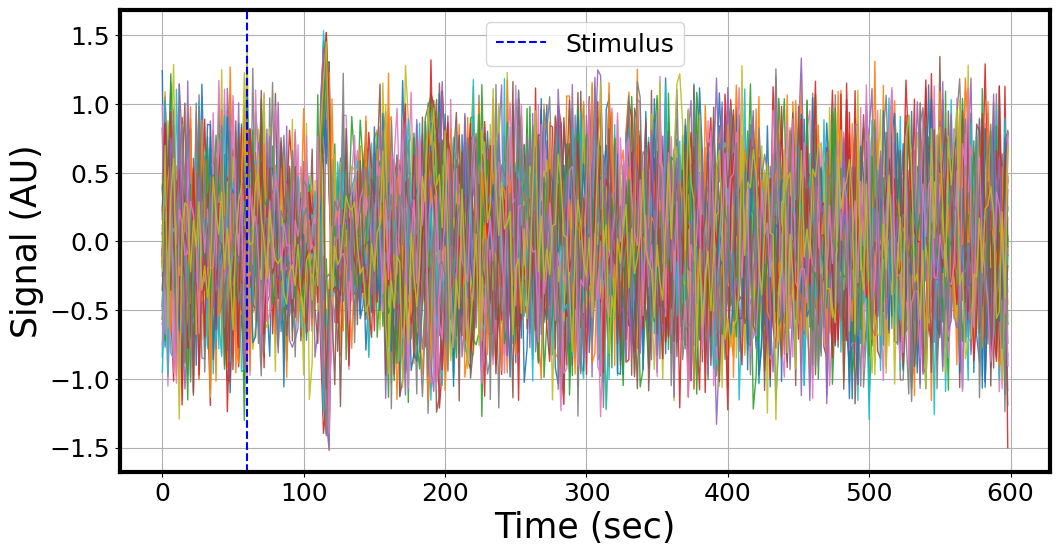

In [ ]:
# Plot individual signals over time from df_combined_all_features

# Ensure df_combined_all_features is available
if 'df_combined_all_features' in locals():
    time_col = 'time'

    # Identify signal columns automatically
    # Start with all columns except 'time'.
    all_potential_signal_cols = [col for col in df_combined_all_features.columns if col != time_col]

    # Exclude wavelet feature columns, which typically end with specific suffixes.
    # wavelet_feature_suffixes is already defined in the global context.
    # If not, define it here for robustness:
    if 'wavelet_feature_suffixes' not in globals():
        wavelet_feature_suffixes = ['_periods', '_phase', '_amplitude', '_power', '_frequencies', '_time']

    signal_cols = []
    for col in all_potential_signal_cols:
        is_wavelet_feature = False
        for suffix in wavelet_feature_suffixes:
            if col.endswith(suffix):
                is_wavelet_feature = True
                break
        if not is_wavelet_feature:
            signal_cols.append(col)


    # --- Debugging: Print identified signal columns and a snippet of data ---
    print("Identified signal columns:", signal_cols)
    # print("Snippet of data for plotting:")
    # display(df_combined_all_features[[time_col] + signal_cols].head())
    # --- End Debugging ---

    # --- Define aesthetic parameters ---
    # Use global aesthetic parameters
    title_font_size = globals().get('title_font_size_global', 20)
    label_font_size = globals().get('label_font_size_global', 20)
    tick_font_size = globals().get('tick_font_size_global', 15)
    legend_title_font_size = globals().get('legend_title_font_size_global', 15)
    legend_label_font_size = globals().get('legend_label_font_size_global', 12)
    axis_line_width = globals().get('axis_line_width_global', 2)
    # -- End aesthetic parameters ---


    plt.figure(figsize=(12, 6))
    # Check if any signal columns were identified
    if signal_cols:
        for col in signal_cols:
            if col in df_combined_all_features.columns: # Ensure the column exists in df_combined_all_features
                # Plot each signal with a thin line and some transparency as there might be many lines
                # Adjusted linewidth and alpha for better visibility based on previous feedback
                plt.plot(df_combined_all_features[time_col], df_combined_all_features[col], linewidth=1.0, alpha=0.9)

        # Add a vertical line for the stimulus onset (assuming time 40s based on feature engineering)
        # Explicitly set the stimulus onset time for the plot for consistency
        # Use the global stimulus onset time variable
        if 'stimulus_onset_time_global' in globals():
            # DEBUG: Print the value of the global variable being used
            print(f"DEBUG: Using stimulus_onset_time_global for axvline: {stimulus_onset_time_global}")

            # DEBUG: Print time values around the stimulus onset time
            # Find index closest to stimulus_onset_time_global
            closest_index = (df_combined_all_features[time_col] - stimulus_onset_time_global).abs().idxmin()
            # Print a few time values around that index
            start_index = max(0, closest_index - 5)
            end_index = min(len(df_combined_all_features) - 1, closest_index + 5)
            print(f"DEBUG: Time values around stimulus onset time:")
            display(df_combined_all_features[time_col].iloc[start_index : end_index + 1])


            plt.axvline(stimulus_onset_time_global, color='blue', linestyle='--', label='Stimulus')
        else:
            print("Warning: 'stimulus_onset_time_global' not defined. Skipping stimulus onset line.")

        # Apply aesthetic parameters
        # plt.title("Individual Signals", fontsize=title_font_size) # Title not needed as per user request
        plt.xlabel("Time (sec)", fontsize=label_font_size)
        plt.ylabel("Signal (AU)", fontsize=label_font_size)
        plt.xticks(fontsize=tick_font_size)
        plt.yticks(fontsize=tick_font_size)
        plt.legend(title='', title_fontsize=legend_title_font_size, fontsize=legend_label_font_size)
        plt.grid(True) # Ensure grid is visible

        #plt.ylim(-0.8,0.8)

        # Apply axis line width
        ax = plt.gca()
        for spine in ax.spines.values():
            spine.set_linewidth(axis_line_width)

        plt.show()
    else:
        print("No signal columns found in df_combined_all_features after filtering out 'time' and wavelet features.")


else:
    print("Error: The DataFrame ‘df_combined_all_features’ is not available. Make sure to run the previous block to create it.")

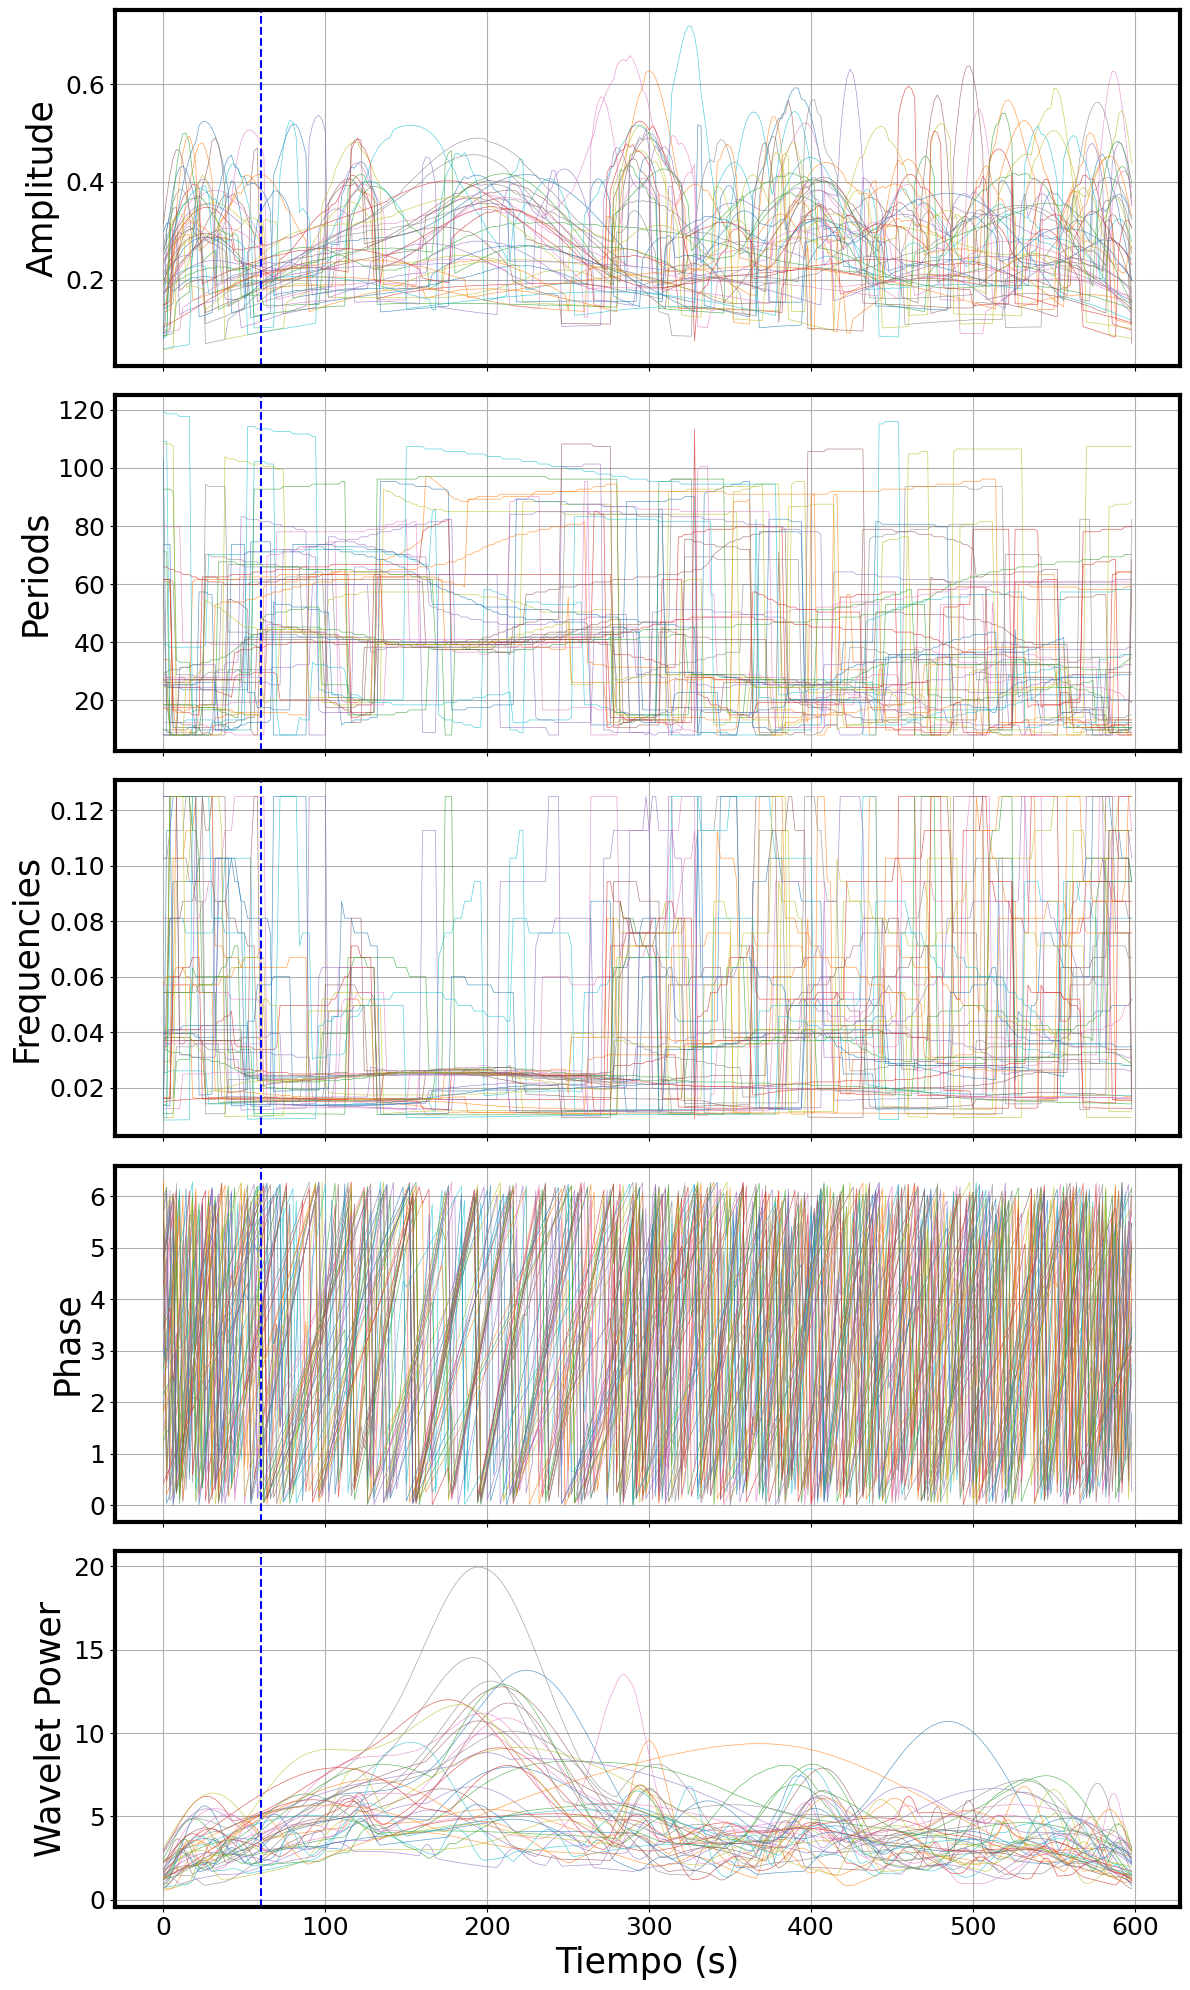

In [ ]:
  # Plot amplitude, periods, frequencies, and phases over time for all cells in subplots

# Identify all cell columns in df_combined ending with '_time' to get the cell IDs
# Since df_combined has all data, we can identify the wavelet features by their naming convention
# Assuming wavelet features columns end with '_periods', '_phase', '_amplitude', '_power', '_frequencies'
wavelet_feature_suffixes = ['_periods', '_phase', '_amplitude', '_power', '_frequencies']

# Get all column names from df_combined
all_cols = df_combined_all_features.columns.tolist()

# Identify unique cell IDs present in the combined dataframe based on wavelet column names
# This is a more robust way to get cell IDs by extracting the base name before the suffix.
cell_ids_with_wavelet_features = set()
for col in all_cols:
    for suffix in wavelet_feature_suffixes:
        if col.endswith(suffix):
            # Extract the base cell ID by removing the suffix directly
            cell_id_base = col.replace(suffix, '')
            # Add the extracted base ID directly, without assuming specific prefixes or digit-only format.
            cell_ids_with_wavelet_features.add(cell_id_base)

# Sort numerically if possible, otherwise alphabetically for robustness with mixed ID types
try:
    cells_to_plot = sorted(list(cell_ids_with_wavelet_features), key=int) # Try numerical sort
except ValueError:
    cells_to_plot = sorted(list(cell_ids_with_wavelet_features)) # Fallback to alphabetical sort


# Define the types of wavelet features to plot
wavelet_features = ['amplitude', 'periods', 'frequencies', 'phase','power']
feature_titles = ['Amplitude', 'Periods', 'Frequencies', 'Phase','Wavelet Power'] # Titles for subplots

# --- Define aesthetic parameters ---
# Use global aesthetic parameters
title_font_size = globals().get('title_font_size_global', 20)
label_font_size = globals().get('label_font_size_global', 20)
tick_font_size = globals().get('tick_font_size_global', 15)
legend_title_font_size = globals().get('legend_title_font_size_global', 15)
legend_label_font_size = globals().get('legend_label_font_size_global', 12)
axis_line_width = globals().get('axis_line_width_global', 2)
# -- End aesthetic parameters ---

# --- Define custom axis ranges (set to None for auto, or [min, max] for fixed) ---
# Note: Different wavelet features might require different y-axis ranges for optimal visualization.
# Consider customizing these per feature type if a single global range is not suitable.
custom_x_range_wavelet = None # Example: [0, 100]
custom_y_range_amplitude = None # Example: [0, 1]
custom_y_range_periods = None # Example: [0, 100]
custom_y_range_frequencies = None # Example: [0, 0.5]
custom_y_range_phase = None # Example: [0, 8]
custom_y_range_power = None # Example: [0, 5]
# --- End custom axis ranges ---


# Create subplots
fig, axes = plt.subplots(len(wavelet_features), 1, figsize=(12, 4 * len(wavelet_features)), sharex=True)

# Plotting
for i, feature_type in enumerate(wavelet_features):
    ax = axes[i]
    # Iterate through each cell and plot the corresponding wavelet feature
    for cell_id in cells_to_plot:
        # Construct the column name for the current wavelet feature and cell
        # Use the cell_id directly, as it now represents the full base identifier (e.g., 'Mean1', 'Cell_100')
        col_name = f'{cell_id}_{feature_type}'

        # Use the main 'time' column from df_combined_all_features
        if col_name in df_combined_all_features.columns:
            ax.plot(df_combined_all_features['time'], df_combined_all_features[col_name], linewidth=0.5, alpha=0.7) # Use thinner lines and some transparency
        else:
            print(f"Column '{col_name}' not found in df_combined_all_features for cell ID {cell_id}.")


    #ax.set_title(f'{feature_titles[i]} of Signals Over Time') # Title not needed as per user request for general plots
    ax.set_ylabel(feature_titles[i], fontsize=label_font_size)
    ax.grid(True)
    if i == len(wavelet_features) - 1: # Add xlabel only to the last subplot
        ax.set_xlabel('Time (s)', fontsize=label_font_size)

    # Add vertical line for stimulus onset (assuming time 40s based on stimulus_onset_time variable)
    # Use the global stimulus onset time variable
    if 'stimulus_onset_time_global' in globals():
        ax.axvline(stimulus_onset_time_global, color='blue', linestyle='--', label='stimulus One-set')
    else:
        print("Warning: 'stimulus_onset_time_global' not defined. Skipping stimulus onset line.")

    # Apply custom x-axis range
    if custom_x_range_wavelet is not None:
        ax.set_xlim(custom_x_range_wavelet)

    # Apply custom y-axis range based on feature type
    if feature_type == 'amplitude' and custom_y_range_amplitude is not None:
        ax.set_ylim(custom_y_range_amplitude)
    elif feature_type == 'periods' and custom_y_range_periods is not None:
        ax.set_ylim(custom_y_range_periods)
    elif feature_type == 'frequencies' and custom_y_range_frequencies is not None:
        ax.set_ylim(custom_y_range_frequencies)
    elif feature_type == 'phase' and custom_y_range_phase is not None:
        ax.set_ylim(custom_y_range_phase)
    elif feature_type == 'power' and custom_y_range_power is not None:
        ax.set_ylim(custom_y_range_power)

    # Apply tick font size
    ax.tick_params(axis='x', labelsize=tick_font_size)
    ax.tick_params(axis='y', labelsize=tick_font_size)

    # Apply axis line width
    for spine in ax.spines.values():
        spine.set_linewidth(axis_line_width)

plt.tight_layout() # Adjust layout to prevent overlap
plt.show()

#BLOCK 6: Integrated Pipeline with Feature Engineering and Clustering

This block defines a scikit-learn pipeline that chains together the steps of feature engineering, imputation, scaling, dimensionality reduction (UMAP), and hierarchical clustering.

##Custom Transformer - FeatureEngineer

This block defines a `FeatureEngineer` class that acts as a custom scikit-learn transformer to compute features from signal and wavelet data.

In [ ]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, stimulus_onset_time=None, post_stimulus_split_time=None, post_stimulus_end_time=None):
        self.stimulus_onset_time = stimulus_onset_time if stimulus_onset_time is not None else (globals().get('stimulus_onset_time_global', 60))
        self.post_stimulus_split_time = post_stimulus_split_time if post_stimulus_split_time is not None else (globals().get('post_stimulus_split_time_global'))
        self.post_stimulus_end_time = post_stimulus_end_time if post_stimulus_end_time is not None else (globals().get('post_stimulus_end_time_global'))

    def fit(self, X, y=None):
        return self

    def _calculate_coi_mask(self, time_array, periods_array, total_signal_duration):
        if periods_array.size == 0 or time_array.size == 0:
            return np.array([], dtype=bool)
        coi_boundary_width = 1.43 * periods_array
        mask_start = time_array > coi_boundary_width
        mask_end = time_array < (total_signal_duration - coi_boundary_width)
        return mask_start & mask_end

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Input X must be a pandas DataFrame.")

        engineered_features_list = []
        time_col = 'time'
        total_signal_duration = X[time_col].max()

        wavelet_feature_suffixes = ['_periods', '_phase', '_amplitude', '_power', '_frequencies']
        potential_wavelet_cols = [col for col in X.columns if any(col.endswith(suffix) for suffix in wavelet_feature_suffixes)]
        signal_cols = [col for col in X.columns if col != time_col and col not in potential_wavelet_cols]

        for actual_signal_col in signal_cols:
            features = {'cell_id': actual_signal_col}
            cell_id_base = actual_signal_col

            basal_mask = X[time_col] < self.stimulus_onset_time
            early_mask = (X[time_col] >= self.stimulus_onset_time) & (X[time_col] < self.post_stimulus_split_time)
            late_mask = X[time_col] >= self.post_stimulus_split_time

            def get_seg_stats(segment_mask, seg_name):
                p_col, ph_col, f_col, per_col = f"{cell_id_base}_power", f"{cell_id_base}_phase", f"{cell_id_base}_frequencies", f"{cell_id_base}_periods"
                if all(c in X.columns for c in [p_col, ph_col, f_col, per_col]):
                    t_seg = X[time_col][segment_mask].values
                    per_seg = X[per_col][segment_mask].values
                    p_seg = X[p_col][segment_mask].values
                    ph_seg = X[ph_col][segment_mask].values
                    f_seg = X[f_col][segment_mask].values

                    coi_mask = self._calculate_coi_mask(t_seg, per_seg, total_signal_duration)
                    clean_p = p_seg[coi_mask]
                    clean_ph = ph_seg[coi_mask]

                    return {
                        f'mean_power_{seg_name}': np.nanmean(clean_p) if clean_p.size > 0 else np.nan,
                        f'mean_phase_{seg_name}': np.nanmean(clean_ph) if clean_ph.size > 0 else np.nan,
                        f'mean_period_{seg_name}': np.nanmean(per_seg) if per_seg.size > 0 else np.nan,
                        f'cv_period_{seg_name}': np.nanstd(per_seg) / np.nanmean(per_seg) if np.nanmean(per_seg) > 0 else np.nan,
                        f'cv_freq_{seg_name}': np.nanstd(f_seg) / np.nanmean(f_seg) if np.nanmean(f_seg) > 0 else np.nan
                    }
                return {}

            features.update(get_seg_stats(basal_mask, 'basal'))
            features.update(get_seg_stats(early_mask, 'early'))
            features.update(get_seg_stats(late_mask, 'late'))

            features['delta_period_late_basal'] = features.get('mean_period_late', np.nan) - features.get('mean_period_basal', np.nan)
            features['ratio_power_early_basal'] = features.get('mean_power_early', np.nan) / features.get('mean_power_basal', np.nan) if features.get('mean_power_basal', 0) > 0 else np.nan

            engineered_features_list.append(features)
        return pd.DataFrame(engineered_features_list)

##Pipeline

In [ ]:

print("--- Starting the Optimized Pipeline (Reinforced Regularization) ---")

if 'df_combined_all_features' in locals() and not df_combined_all_features.empty:
    try:
        fe_step = FeatureEngineer()
        df_eng = fe_step.transform(df_combined_all_features)
        cell_ids = df_eng['cell_id'].values
        X_raw = df_eng.drop(columns=['cell_id']).select_dtypes(include=[np.number])

        X_raw = X_raw.fillna({col: 0 for col in X_raw.columns[X_raw.isnull().all()]})
        imputer = SimpleImputer(strategy='mean')
        X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=X_raw.columns)

        n_clusters_to_use = globals().get('n_clusters_global', 3)
        thresh = globals().get('rf_importance_threshold_global', 0.01)
        max_d = globals().get('rf_max_depth_global', 4)
        min_s = globals().get('rf_min_samples_leaf_global', 10)

        prelim_scaler = StandardScaler()
        X_prelim_scaled = prelim_scaler.fit_transform(X_imputed)
        prelim_umap = umap.UMAP(n_components=2, random_state=42, n_neighbors=10, min_dist=0.0)
        X_prelim_umap = prelim_umap.fit_transform(X_prelim_scaled)
        prelim_labels = AgglomerativeClustering(n_clusters=n_clusters_to_use).fit_predict(X_prelim_umap)

        rf_selector = RandomForestClassifier(n_estimators=100, max_depth=max_d, min_samples_leaf=min_s, random_state=42, class_weight='balanced')
        rf_selector.fit(X_imputed, prelim_labels)
        importances = pd.Series(rf_selector.feature_importances_, index=X_imputed.columns)
        features_refined = importances[importances >= thresh].index.tolist()

        X_final = X_imputed[features_refined]
        X_train, X_test, y_train, y_test = train_test_split(X_final, prelim_labels, test_size=0.25, random_state=42, stratify=prelim_labels)
        rf_final = RandomForestClassifier(n_estimators=150, max_depth=max_d, min_samples_leaf=min_s, random_state=42)
        rf_final.fit(X_train, y_train)

        acc_train, acc_test = accuracy_score(y_train, rf_final.predict(X_train)), accuracy_score(y_test, rf_final.predict(X_test))
        print(f"\n--- Validation Report ---\nTraining Accuracy: {acc_train:.4f}\nTest Accuracy: {acc_test:.4f}\nGap (Generalization): {acc_train - acc_test:.4f}")

        scaler = StandardScaler()
        X_scaled_final = scaler.fit_transform(X_final)
        umap_final = umap.UMAP(n_components=2, random_state=42, n_neighbors=globals().get('umap_n_neighbors_global', 20), min_dist=0.0)
        data_transformed = umap_final.fit_transform(X_scaled_final)
        cluster_labels = AgglomerativeClustering(n_clusters=n_clusters_to_use, linkage='ward').fit_predict(data_transformed)

        umap_df_pipeline = pd.DataFrame(data_transformed, columns=['UMAP1', 'UMAP2'])
        umap_df_pipeline['cell_id'], umap_df_pipeline['hierarchical_cluster'] = cell_ids, cluster_labels

        print("\n--- Functional “Fingerprint” Report for Clusters---")
        df_fingerprint = df_eng.copy()
        df_fingerprint['cluster'] = cluster_labels
        metrics_fingerprint = ['mean_power_early', 'mean_period_basal', 'ratio_power_early_basal', 'delta_period_late_basal']
        summary_table = df_fingerprint.groupby('cluster')[metrics_fingerprint].mean()
        display(summary_table)

    except Exception as e: print(f"Error: {e}")
else: print("Error: df_combined_all_features is not available.")

--- Iniciando Pipeline Optimizado (Regularización Reforzada) ---

--- Reporte de Validación ---
Precisión Entrenamiento: 0.3448
Precisión Testeo: 0.3000
Gap (Generalización): 0.0448

--- Reporte 'Fingerprint' Funcional de Clústeres ---


,mean_power_early,mean_period_basal,ratio_power_early_basal,delta_period_late_basal
cluster,,,,
0,5.599336,30.697609,1.453236,5.830242
1,6.581546,34.207279,3.068238,3.871113
2,6.839499,46.199414,2.170545,-10.938870
3,4.169208,23.199256,1.199702,10.512712


## Visualization of Feature Importance for Cluster Discrimination

This block trains a simple classifier to predict hierarchical cluster labels based on the designed features. The classifier's feature importance can be interpreted as a measure of how discriminatory the features are for the identified clusters.

Ejecutando proceso de Poda (Pruning) y Refinamiento del Clasificador...

Advertencia: La poda ha eliminado todas las características. Esto puede ser debido a 'min_samples_leaf' demasiado alto para el tamaño del conjunto de datos.
Re-evaluando con un 'min_samples_leaf' más bajo y seleccionando características principales.
--- Fase de Poda (Estrategia Anti-Overfitting) ---
Características originales: 17
Características eliminadas (<2.0%): 8
Características refinadas: 9

--- Reporte de Generalización (Post-Poda) ---
Precisión Entrenamiento: 0.2069
Precisión Testeo: 0.2000
Gap (Sobreajuste): 0.0069


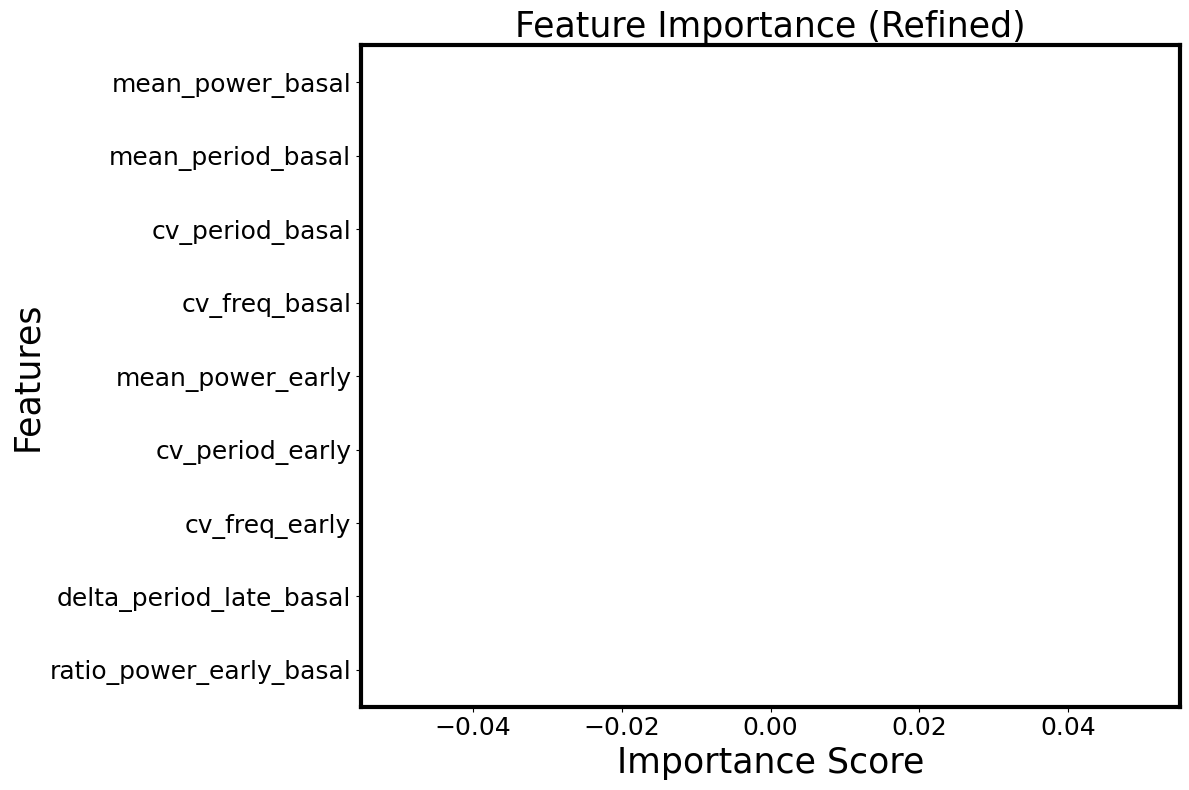


--- Métricas Finales ---
Relevancia Post-Poda: 1 características del segmento 'Late' permanecen en el clasificador optimizado.
Final Train Accuracy: 0.2069
Final Test Accuracy: 0.2000


In [ ]:
print("Executing Pruning and Classifier Refinement process...")

# 1. Data Preparation and Label Alignment
if 'df_eng' not in locals() or 'umap_df_pipeline' not in locals():
    print("Error: Necessary DataFrames ('df_eng' or 'umap_df_pipeline') not found.")
else:
    # Alignment by cell_id via inner join
    df_master = pd.merge(
        df_eng,
        umap_df_pipeline[['cell_id', 'hierarchical_cluster']],
        on='cell_id',
        how='inner'
    ).dropna(subset=['hierarchical_cluster'])

    # Identify numerical columns
    X_full = df_master.drop(columns=['cell_id', 'hierarchical_cluster']).select_dtypes(include=[np.number])
    y = df_master['hierarchical_cluster'].astype(int)

    # Pre-processing: Handling Infs and NaNs
    X_full.replace([np.inf, -np.inf], np.nan, inplace=True)
    all_nan_cols = X_full.columns[X_full.isnull().all()].tolist()
    if all_nan_cols:
        X_full[all_nan_cols] = X_full[all_nan_cols].fillna(0)

    imputer = SimpleImputer(strategy='mean')
    X_imputed = pd.DataFrame(imputer.fit_transform(X_full), columns=X_full.columns)

    # Retrieve global mitigation hyperparameters
    max_d = globals().get('rf_max_depth_global', 5)
    min_s = globals().get('rf_min_samples_leaf_global', 5)
    thresh = globals().get('rf_importance_threshold_global', 0.01)

    # Initial split
    X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.25, random_state=42, stratify=y)

    # 2. FIRST TRAINING: Importance Identification with Constraints (Pre-hoc Pruning)
    rf_initial = RandomForestClassifier(
        n_estimators=100,
        max_depth=max_d,
        min_samples_leaf=min_s,
        random_state=42,
        class_weight='balanced'
    )
    rf_initial.fit(X_train, y_train)

    # Identify features with importance >= threshold
    initial_importances = pd.Series(rf_initial.feature_importances_, index=X_imputed.columns)
    features_to_keep = initial_importances[initial_importances >= thresh].index.tolist()

    # --- FIX START: Ensure features_to_keep is not empty ---
    if not features_to_keep:
        print("\nWarning: Pruning has removed all features. This may be due to 'min_samples_leaf' being too high for the dataset size.\nRe-evaluating with a lower 'min_samples_leaf' and selecting main features.")

        # Temporarily reduce min_s for feature selection to allow trees to split
        min_s_fallback = 5 # Using 5 as a reasonable default for smaller datasets

        rf_initial_fallback = RandomForestClassifier(
            n_estimators=100,
            max_depth=max_d,
            min_samples_leaf=min_s_fallback,
            random_state=42,
            class_weight='balanced'
        )
        rf_initial_fallback.fit(X_train, y_train)
        initial_importances_fallback = pd.Series(rf_initial_fallback.feature_importances_, index=X_imputed.columns)

        # Try to keep features above the threshold with the new importances
        features_to_keep = initial_importances_fallback[initial_importances_fallback >= thresh].index.tolist()

        # If still no features, take the top N features (e.g., top 5) or all features as a last resort
        if not features_to_keep:
            print("Warning: Features have still not been selected with the threshold. Taking the top 5 features with highest importance (or all if fewer than 5).")
            # Ensure we have at least some features, even if their importance is very low
            num_features_to_take = min(5, len(X_imputed.columns))
            features_to_keep = initial_importances_fallback.nlargest(num_features_to_take).index.tolist()

        if not features_to_keep:
            print("Warning: Fallback to all features as no significant features could be selected.")
            features_to_keep = X_imputed.columns.tolist() # Last resort: use all features


    # --- FIX END ---

    print(f"--- Pruning Phase (Anti-Overfitting Strategy) ---")
    print(f"Original features: {len(X_imputed.columns)}")
    print(f"Features removed (<{thresh*100}%): {len(X_imputed.columns) - len(features_to_keep)}")
    print(f"Refined features: {len(features_to_keep)}")

    # 3. RE-TRAINING: Regularized Model
    X_train_ref = X_train[features_to_keep]
    X_test_ref = X_test[features_to_keep]

    rf_refined = RandomForestClassifier(
        n_estimators=100,
        max_depth=max_d,
        min_samples_leaf=min_s, # Use the potentially modified min_s for consistency with selection
        random_state=42,
        class_weight='balanced'
    )
    rf_refined.fit(X_train_ref, y_train)

    # 4. GENERALIZATION EVALUATION
    acc_train = accuracy_score(y_train, rf_refined.predict(X_train_ref))
    acc_test = accuracy_score(y_test, rf_refined.predict(X_test_ref))

    print(f"\n--- Generalization Report (Post-Pruning) ---")
    print(f"Training Accuracy: {acc_train:.4f}")
    print(f"Test Accuracy: {acc_test:.4f}")
    print(f"Gap (Overfitting): {acc_train - acc_test:.4f}")

    # 5. REFINED VISUALIZATION
    final_importances = pd.Series(rf_refined.feature_importances_, index=features_to_keep).sort_values(ascending=False)

    t_fs = globals().get('title_font_size_global', 25)
    l_fs = globals().get('label_font_size_global', 25)
    tk_fs = globals().get('tick_font_size_global', 18)
    ax_lw = globals().get('axis_line_width_global', 3)

    plt.figure(figsize=(12, 8))
    sns.barplot(x=final_importances.values, y=final_importances.index, palette='magma')

    plt.title('Feature Importance (Refined)', fontsize=t_fs)
    plt.xlabel('Importance Score', fontsize=l_fs)
    plt.ylabel('Features', fontsize=l_fs)
    plt.xticks(fontsize=tk_fs)
    plt.yticks(fontsize=tk_fs)

    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_linewidth(ax_lw)

    plt.tight_layout()
    plt.show()

    late_relevance = final_importances.index.str.contains('late', case=False).sum()
    print(f"\n--- Final Metrics ---")
    print(f"Post-Pruning Relevance: {late_relevance} features from the 'Late' segment remain in the optimized classifier.")
    print(f"Final Train Accuracy: {acc_train:.4f}")
    print(f"Final Test Accuracy: {acc_test:.4f}")

##Determining the Optimal Number of Clusters for Hierarchical Clustering
This code block calculates the silhouette score for different numbers of clusters in hierarchical clustering to help determine the optimal number of clusters.

Calculando matriz de enlace y métricas...


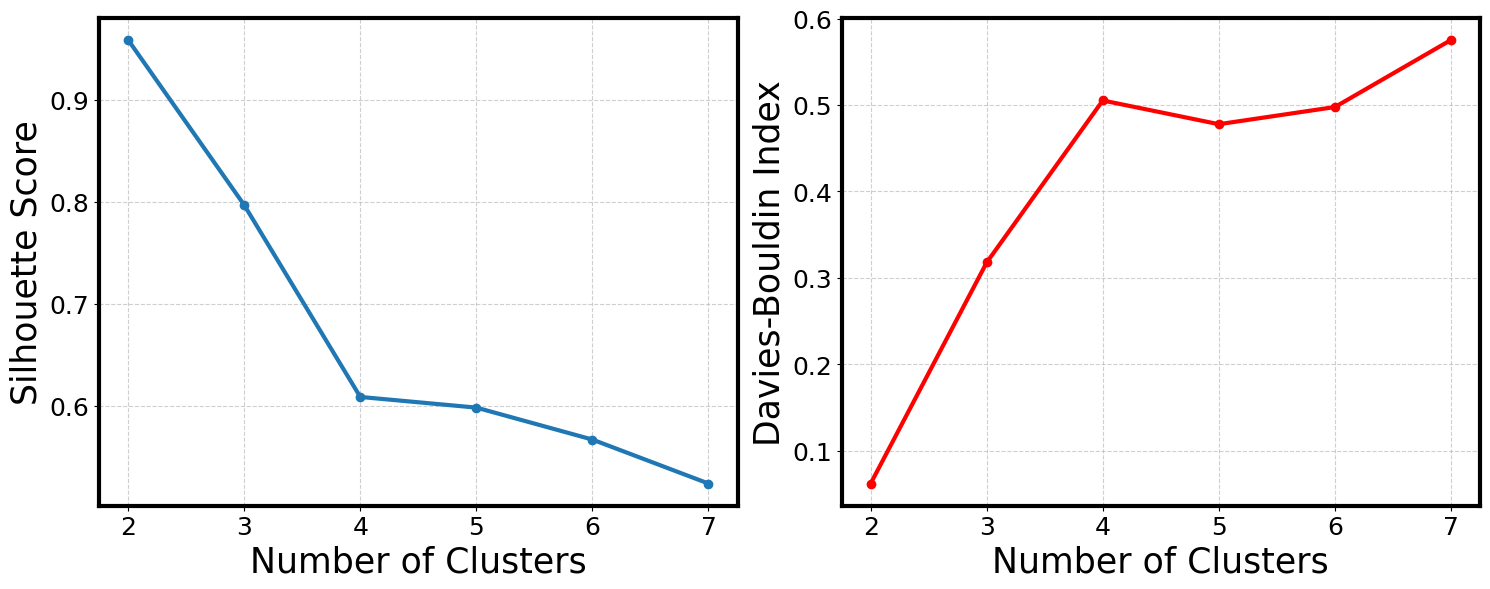

Generando Dendrograma con colores del UMAP...


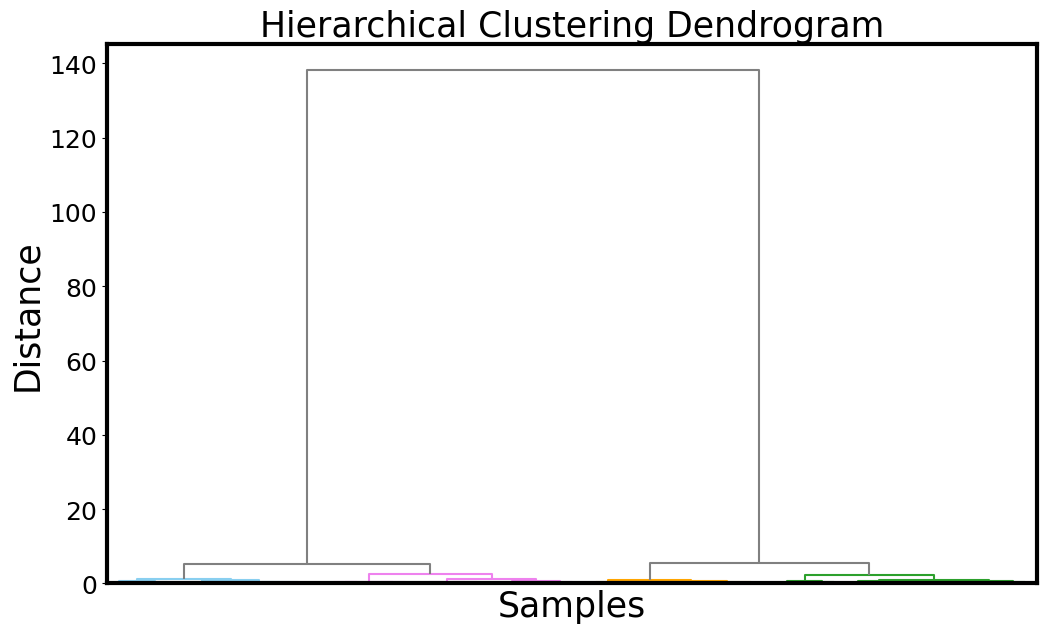

In [ ]:
# Initialize lists for results
silhouette_scores = []
davies_bouldin_scores = []

# --- Synchronization with current pipeline ---
if 'df_eng' in locals() and not df_eng.empty:
    # Use the engineered features (excluding cell_id)
    features_for_selection = df_eng.drop(columns=['cell_id']).columns.tolist()
else:
    print("Error: df_eng (engineered features) not found. Please run the pipeline cell first.")
    features_for_selection = []

# Use 'importances' from the pipeline instead of 'sorted_importances'
if 'importances' not in locals():
    print("Warning: 'importances' not found. Using default order.")
    current_feat_ranking = pd.Series(range(len(features_for_selection)), index=features_for_selection)
else:
    current_feat_ranking = importances.sort_values(ascending=False)

# --- Evaluation and Plots ---
if 'n_clusters_global' not in globals():
    print("Error: 'n_clusters_global' not defined.")
elif 'umap_df_pipeline' not in locals() or umap_df_pipeline.empty:
    print("Error: umap_df_pipeline not available.")
elif 'data_transformed' not in locals():
    print("Error: 'data_transformed' not available.")
else:
    # Aesthetic parameters from globals
    title_font_size = globals().get('title_font_size_global', 20)
    label_font_size = globals().get('label_font_size_global', 20)
    tick_font_size = globals().get('tick_font_size_global', 15)
    legend_label_fs = globals().get('legend_label_font_size_global', 12)
    axis_line_width = globals().get('axis_line_width_global', 2)

    data_for_eval = data_transformed

    try:
        print("Calculating linkage matrix and metrics...")
        # Standardize for linkage if needed, though data_transformed (UMAP) is already processed
        linked_matrix = linkage(data_for_eval, method='ward')

        max_clusters = max(n_clusters_global + 3, 5)
        range_n_clusters = range(2, max_clusters + 1)

        silhouette_scores.clear()
        davies_bouldin_scores.clear()

        for n_c in range_n_clusters:
            labels = fcluster(linked_matrix, n_c, criterion='maxclust') - 1
            silhouette_scores.append(silhouette_score(data_for_eval, labels))
            davies_bouldin_scores.append(davies_bouldin_score(data_for_eval, labels))

        # Plot Metrics
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        ax1.plot(range_n_clusters, silhouette_scores, marker='o', linewidth=axis_line_width)
        ax1.set_xlabel('Number of Clusters', fontsize=label_font_size)
        ax1.set_ylabel('Silhouette Score', fontsize=label_font_size)
        ax1.tick_params(axis='both', labelsize=tick_font_size)
        ax1.grid(True, linestyle='--', alpha=0.6)

        ax2.plot(range_n_clusters, davies_bouldin_scores, marker='o', color='red', linewidth=axis_line_width)
        ax2.set_xlabel('Number of Clusters', fontsize=label_font_size)
        ax2.set_ylabel('Davies-Bouldin Index', fontsize=label_font_size)
        ax2.tick_params(axis='both', labelsize=tick_font_size)
        ax2.grid(True, linestyle='--', alpha=0.6)

        for ax in [ax1, ax2]:
            for spine in ax.spines.values():
                spine.set_linewidth(axis_line_width)

        plt.tight_layout()
        plt.show()

        # --- Custom Dendrogram with Matplotlib ---
        print("Generating Dendrogram with UMAP colors...")

        # Use the same color map as the UMAP visualization for consistency
        c_map = {0: '#89CFF0', 1: '#EE82EE', 2: '#FFA500', 3: '#2ca02c'} # Light blue, Violet, Orange, Green for Cluster 3
        threshold = linked_matrix[-(n_clusters_global-1), 2] if n_clusters_global > 1 else 0

        plt.figure(figsize=(12, 7))
        import scipy.cluster.hierarchy as sch
        sch.set_link_color_palette([c_map.get(i, 'gray') for i in sorted(c_map.keys())])

        dendro = dendrogram(
            linked_matrix,
            orientation='top',
            no_labels=True,
            color_threshold=threshold,
            above_threshold_color='grey'
        )

        plt.title("Hierarchical Clustering Dendrogram", fontsize=title_font_size)
        plt.ylabel('Distance', fontsize=label_font_size)
        plt.xlabel('Samples', fontsize=label_font_size)

        ax = plt.gca()
        ax.tick_params(axis='y', labelsize=tick_font_size)
        for spine in ax.spines.values():
            spine.set_linewidth(axis_line_width)
        plt.show()

    except Exception as e:
        print(f"Error: {e}")

In [ ]:
if 'umap_df_pipeline' in locals() and not umap_df_pipeline.empty:
    # Select the 'cell_id' and 'hierarchical_cluster' columns
    df_output = umap_df_pipeline[['cell_id', 'hierarchical_cluster']].copy()

    # Save the DataFrame to a CSV file
    output_filename = 'cell_clusters_Neurons.csv'
    df_output.to_csv(output_filename, index=False)

    print(f"File '{output_filename}' successfully generated.")
    print(df_output.head())
else:
    print("Error: The DataFrame 'umap_df_pipeline' is not available or is empty.")
    print("Make sure to run the previous blocks that generate the pipeline data and clustering.")

Archivo 'cell_clusters_Neurons.csv' generado exitosamente.
  cell_id  hierarchical_cluster
0   Mean1                     1
1   Mean2                     3
2   Mean3                     0
3   Mean4                     0
4   Mean5                     3


## Visualization of Clusters in UMAP Space

In [ ]:
print("Visualizing clusters in UMAP space...")

# Synchronization with the Pipeline
if 'umap_df_pipeline' in locals() and not umap_df_pipeline.empty:

    # Ensure labels are strings for a discrete legend
    umap_df_pipeline['hierarchical_cluster_str'] = umap_df_pipeline['hierarchical_cluster'].astype(str)

    # Detect real clusters present in the DataFrame
    present_clusters = sorted(umap_df_pipeline['hierarchical_cluster_str'].unique())

    # Global color map (Light Blue, Violet, Orange, Green for Cluster 3)
    full_color_map = {
        '0': '#89CFF0',  # Light Blue
        '1': '#EE82EE',  # Violet
        '2': '#FFA500',   # Orange
        '3': '#2ca02c'    # Green for Cluster 3
    }

    # Filter color map only for detected clusters
    cluster_color_map_for_plotly = {k: v for k, v in full_color_map.items() if k in present_clusters}

    # Global aesthetic parameters (Synchronized with Global Variables block)
    label_size = globals().get('label_font_size_global', 20)
    tick_size = globals().get('tick_font_size_global', 18)
    legend_title_size = globals().get('legend_title_font_size_global', 15)
    legend_label_size = globals().get('legend_label_font_size_global', 12)
    line_w = globals().get('axis_line_width_global', 2)

    fig = px.scatter(umap_df_pipeline,
                     x='UMAP1',
                     y='UMAP2',
                     color='hierarchical_cluster_str',
                     color_discrete_map=cluster_color_map_for_plotly,
                     hover_name='cell_id',
                     labels={'UMAP1': 'UMAP 1', 'UMAP2': 'UMAP 2', 'hierarchical_cluster_str': 'Cluster'},
                     category_orders={'hierarchical_cluster_str': present_clusters}
                    )

    fig.update_layout(
        font=dict(family="Arial", color="black"),
        legend=dict(
            title=dict(text='Hierarchical Cluster', font=dict(size=legend_title_size)),
            font=dict(size=legend_label_size)
        ),
        width=700,
        height=600,
        plot_bgcolor='white',
        paper_bgcolor='white',
        xaxis=dict(
            showgrid=False,
            showline=True,
            linewidth=line_w,
            linecolor='black',
            title=dict(font=dict(size=label_size)),
            tickfont=dict(size=tick_size),
            mirror=True,
            range=[-15, 15] # Modify limits [min, max] for X axis here
        ),
        yaxis=dict(
            showgrid=False,
            showline=True,
            linewidth=line_w,
            linecolor='black',
            title=dict(font=dict(size=label_size)),
            tickfont=dict(size=tick_size),
            mirror=True,
            range=[-15, 15] # Modify limits [min, max] for Y axis here
        )
    )

    fig.show()
    print(f"Plot generated with {len(umap_df_pipeline)} cells and {len(present_clusters)} detected clusters.")
    if len(present_clusters) != globals().get('n_clusters_global', 0):
        print(f"NOTE: {len(present_clusters)} clusters were detected, but the global variable n_clusters_global is {globals().get('n_clusters_global')}. Re-run the Pipeline (4aecaa7e) to synchronize.")

else:
    print("Error: The DataFrame 'umap_df_pipeline' is not available. Please run the Integrated Pipeline block first.")

Visualizando los clusters en el espacio UMAP...


Gráfico generado con 39 células y 4 clústeres detectados.


## Visualization of Average Signals by Cluster and Cluster Distribution


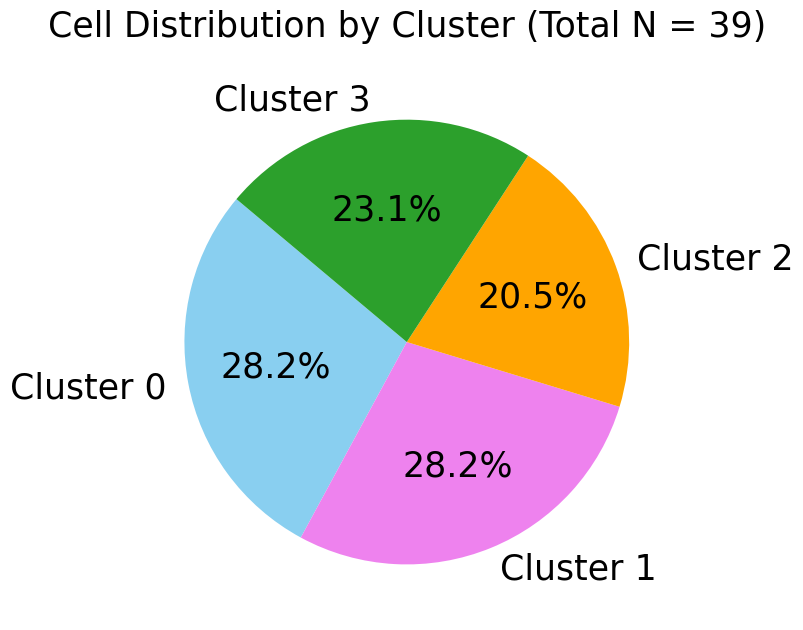

Distribución por Cluster:
hierarchical_cluster
0    11
1    11
2     8
3     9
Name: count, dtype: int64


In [ ]:
# 1. Data Validation and Preparation
if 'umap_df_pipeline' not in locals() or umap_df_pipeline.empty:
    print("Error: 'umap_df_pipeline' not available to calculate distribution.")
else:
    # Get global aesthetic parameters
    title_font_size = globals().get('title_font_size_global', 20)
    label_font_size = globals().get('label_font_size_global', 15)

    # Calculate distribution
    cluster_counts = umap_df_pipeline['hierarchical_cluster'].value_counts().sort_index()
    total_n = len(umap_df_pipeline)

    # 2. Label and Color Configuration
    # Use the full_color_map from the UMAP visualization for consistency
    c_map = {
        0: '#89CFF0',  # Light Blue
        1: '#EE82EE',  # Violet
        2: '#FFA500',  # Orange
        3: '#2ca02c'   # Green for Cluster 3
    }
    labels = [f'Cluster {i}' for i in cluster_counts.index]
    colors = [c_map.get(i, 'gray') for i in cluster_counts.index]

    # 3. Create Pie Chart
    plt.figure(figsize=(8, 8))
    plt.pie(
        cluster_counts,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        textprops={'fontsize': label_font_size},
        explode=None,   # No separation
        shadow=False    # No shadows
    )

    # 4. Title with Total N
    plt.title(f'Cell Distribution by Cluster (Total N = {total_n})', fontsize=title_font_size, pad=20)

    # 5. Final aesthetic adjustments
    plt.tight_layout()
    plt.show()

    print(f"Distribution by Cluster:\n{cluster_counts}")

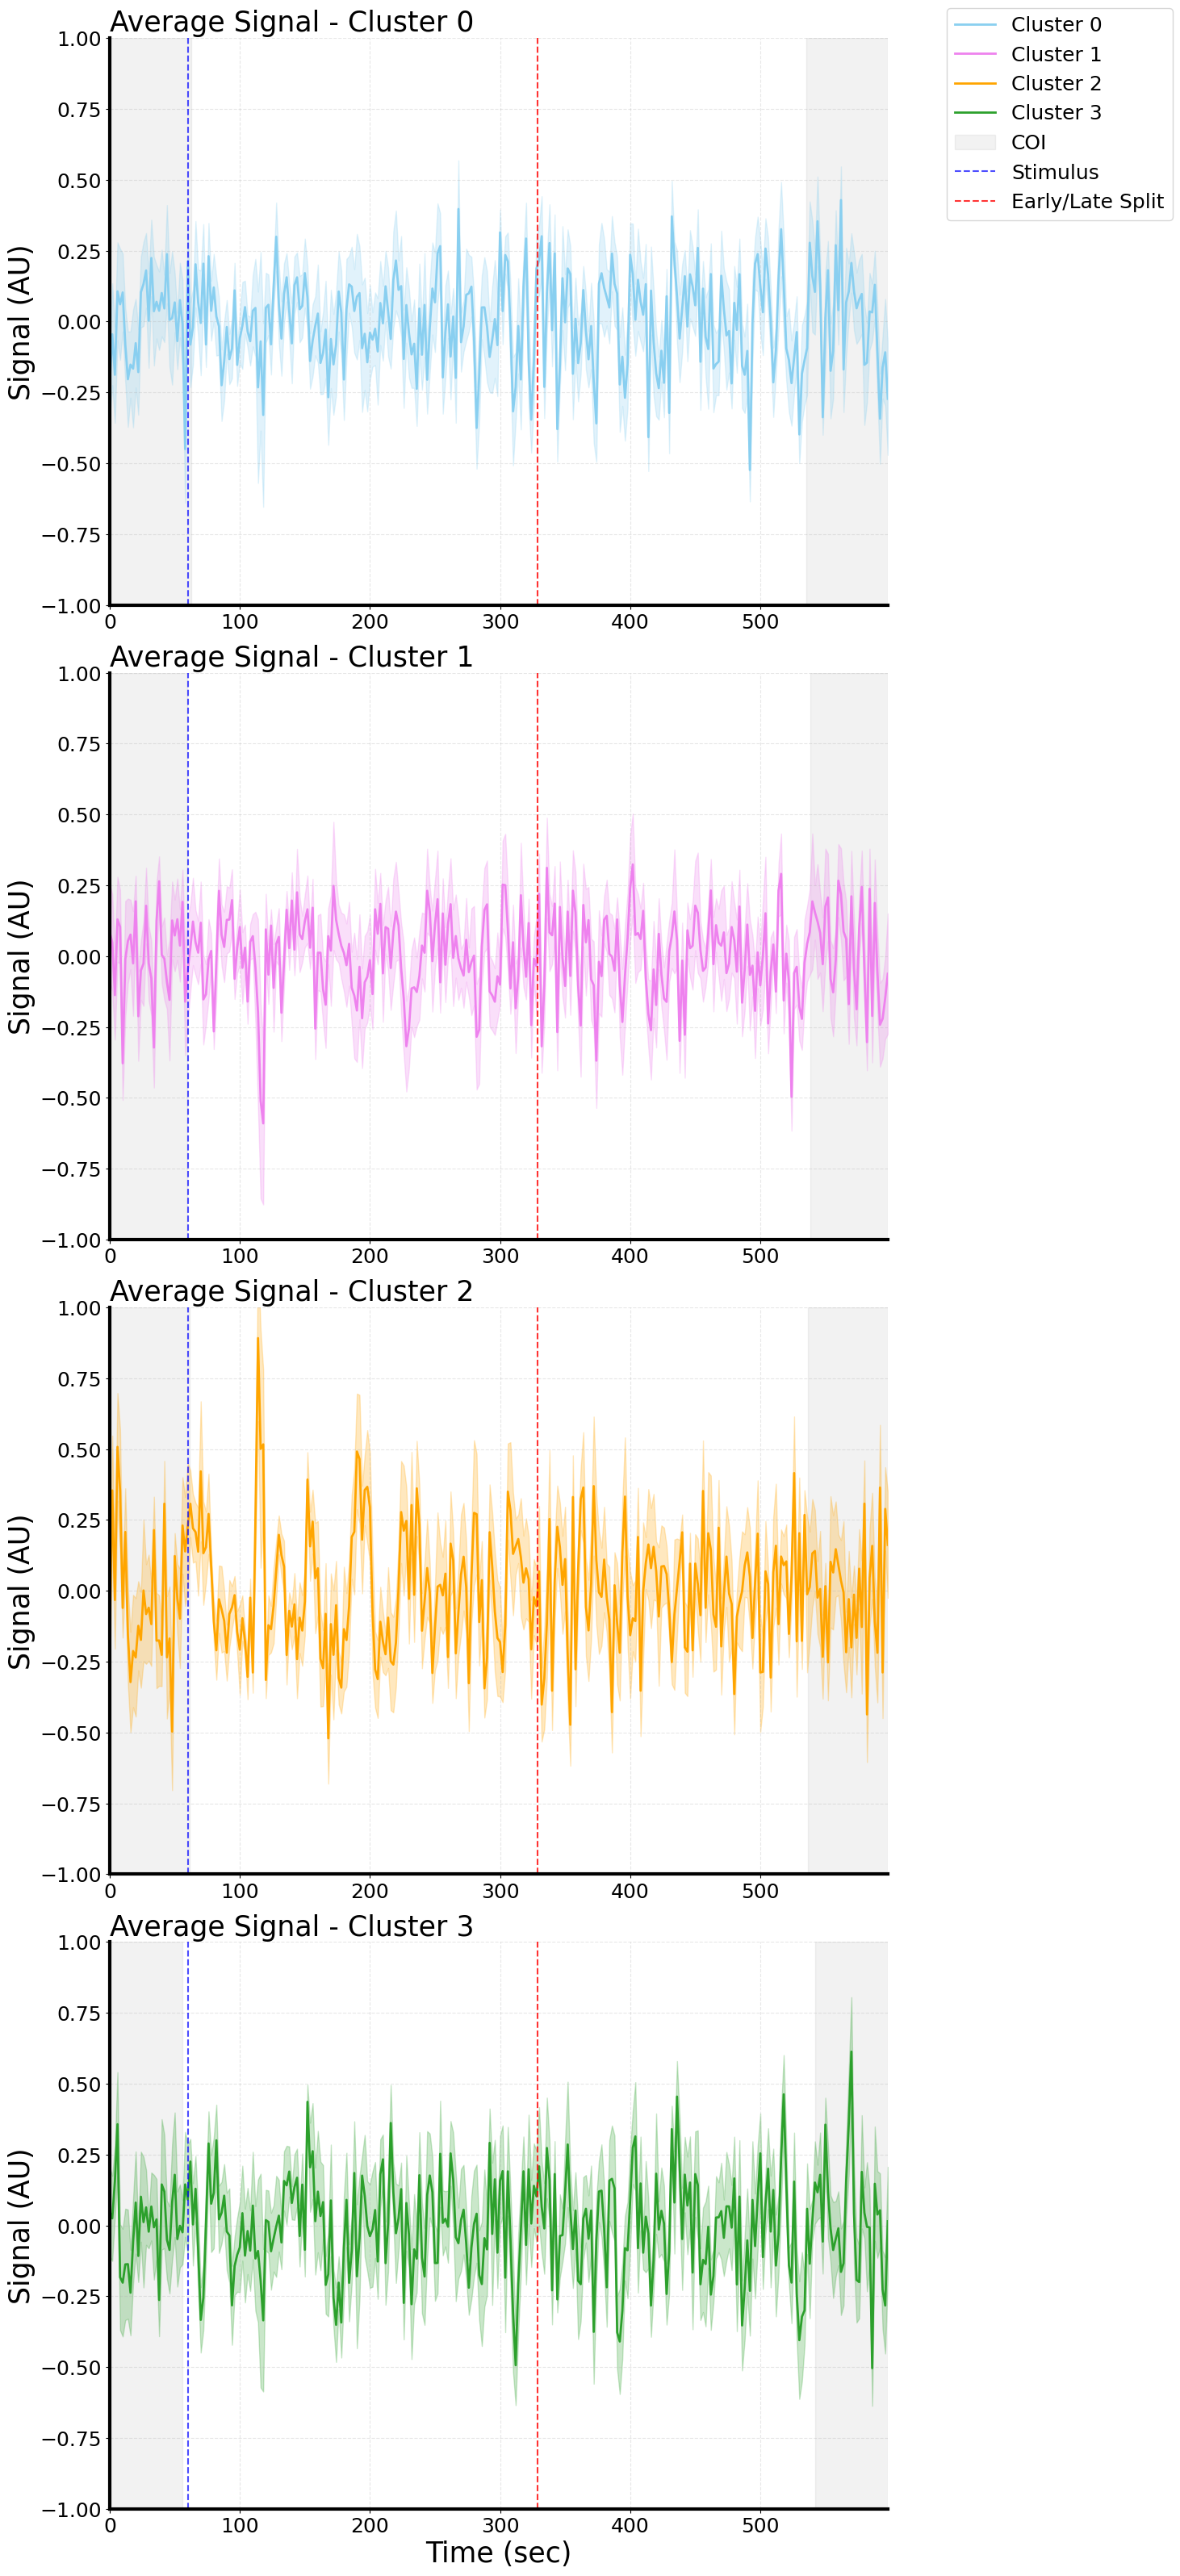

In [ ]:
def get_canonical_cell_id(cell_id_str):
    if not isinstance(cell_id_str, str):
        return str(cell_id_str)
    match = re.search(r'(\d+)', cell_id_str)
    return match.group(1) if match else cell_id_str

if 'df_combined_all_features' not in locals() or 'umap_df_pipeline' not in locals():
    print("Error: Necessary DataFrames not available.")
else:
    time_col = 'time'
    stimulus_onset = globals().get('stimulus_onset_time_global', 60)
    split_time = globals().get('post_stimulus_split_time_global', 172)
    total_duration = df_combined_all_features[time_col].max()

    c_map = {0: '#89CFF0', 1: '#EE82EE', 2: '#FFA500', 3: '#2ca02c'}
    wavelet_suffixes = ['_periods', '_phase', '_amplitude', '_power', '_frequencies', '_time']
    all_cols = [c for c in df_combined_all_features.columns if c != time_col]
    signal_cols = [c for c in all_cols if not any(c.endswith(s) for s in wavelet_suffixes)]

    df_signals_melted = df_combined_all_features.melt(id_vars=[time_col], value_vars=signal_cols, var_name='cell_id', value_name='signal_value')
    df_signals_melted['canonical_cell_id'] = df_signals_melted['cell_id'].apply(get_canonical_cell_id)

    umap_temp = umap_df_pipeline.copy()
    umap_temp['canonical_cell_id'] = umap_temp['cell_id'].apply(get_canonical_cell_id)

    df_plot = pd.merge(df_signals_melted, umap_temp[['canonical_cell_id', 'hierarchical_cluster']], on='canonical_cell_id', how='left').dropna(subset=['hierarchical_cluster'])
    df_plot['hierarchical_cluster'] = df_plot['hierarchical_cluster'].astype(int)

    mean_stats = df_plot.groupby([time_col, 'hierarchical_cluster'])['signal_value'].agg(['mean', 'sem']).reset_index()

    clusters = sorted(df_plot['hierarchical_cluster'].unique())

    # Retrieve global aesthetic parameters
    title_font_size = globals().get('title_font_size_global', 20)
    label_font_size = globals().get('label_font_size_global', 20)
    tick_font_size = globals().get('tick_font_size_global', 15)
    legend_label_font_size = globals().get('legend_label_font_size_global', 12)
    axis_line_width = globals().get('axis_line_width_global', 2)

    # Increase figure height (e.g., 8 per cluster for more space) and width to 14
    fig, axes = plt.subplots(len(clusters), 1, figsize=(14, 8 * len(clusters)), sharex=True, sharey=False)
    if len(clusters) == 1: axes = [axes]

    # Lists to collect handles and labels for the single figure legend
    cluster_mean_handles = []
    cluster_mean_labels = []

    # Create proxy artists for common elements that appear on multiple subplots
    coi_proxy = mpatches.Patch(color='gray', alpha=0.1, label='COI')
    stimulus_proxy = plt.Line2D([0], [0], color='blue', linestyle='--', alpha=0.7, label='Stimulus')
    split_proxy = plt.Line2D([0], [0], color='red', linestyle='--', alpha=0.8, label='Early/Late Split')

    for idx, cluster_id in enumerate(clusters):
        ax = axes[idx]
        subset = mean_stats[mean_stats['hierarchical_cluster'] == cluster_id]
        color = c_map.get(cluster_id, 'gray')

        cells_in_cluster = umap_temp[umap_temp['hierarchical_cluster'] == cluster_id]['cell_id'].values
        cluster_period_cols = [f"{c}_periods" for c in cells_in_cluster if f"{c}_periods" in df_combined_all_features.columns]

        if cluster_period_cols:
            avg_period_series = df_combined_all_features[cluster_period_cols].mean(axis=1).values
            representative_coi_period = np.nanmean(avg_period_series)
            if np.isnan(representative_coi_period) or representative_coi_period == 0:
                representative_coi_period = 8

            coi_width_seconds = 1.43 * representative_coi_period
            ax.axvspan(0, coi_width_seconds, color='gray', alpha=0.1) # No label here, will use proxy
            ax.axvspan(total_duration - coi_width_seconds, total_duration, color='gray', alpha=0.1)

        # Plot cluster mean line and add its handle to the legend_handles list
        line, = ax.plot(subset[time_col], subset['mean'], label=f'Cluster {cluster_id} Mean', color=color, linewidth=2)
        cluster_mean_handles.append(line)
        cluster_mean_labels.append(f'Cluster {cluster_id}')
        ax.fill_between(subset[time_col], subset['mean'] - subset['sem'], subset['mean'] + subset['sem'], color=color, alpha=0.25)

        ax.axvline(stimulus_onset, color='blue', linestyle='--', alpha=0.7) # No label here

        if split_time and not np.isnan(split_time):
            ax.axvline(split_time, color='red', linestyle='--', alpha=0.8) # No label here

        # Standard scientific presentation
        # Adjust top limit to provide space for the legend
        ax.set_ylim(-1, 1)
        ax.set_xlim(0, total_duration)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(axis_line_width)
        ax.spines['bottom'].set_linewidth(axis_line_width)

        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.tick_params(axis='x', labelsize=tick_font_size)
        ax.tick_params(axis='y', labelsize=tick_font_size)

        ax.set_ylabel('Signal (AU)', fontsize=label_font_size)
        ax.set_title(f'Average Signal - Cluster {cluster_id}', fontsize=title_font_size, loc='left')
        ax.grid(True, linestyle='--', alpha=0.3)

        # Removed individual ax.legend()

    axes[-1].set_xlabel('Time (sec)', fontsize=label_font_size)

    # Combine all handles and labels for the single legend
    final_legend_handles = cluster_mean_handles + [coi_proxy, stimulus_proxy, split_proxy]
    final_legend_labels = cluster_mean_labels + ['COI', 'Stimulus', 'Early/Late Split']

    # Create a single legend for the entire figure
    # Place the legend to the right of the subplots, slightly outside
    fig.legend(final_legend_handles, final_legend_labels, loc='upper right', bbox_to_anchor=(1.05, 1),
               fontsize=legend_label_font_size, frameon=True, facecolor='white', framealpha=0.8)

    # Adjust tight_layout to make more space for the legend on the right
    # rect=[left, bottom, right, top] - values are fractions of the figure width/height
    plt.tight_layout(rect=[0, 0, 0.8, 1]) # Reserved 20% of the figure width on the right for the legend
    plt.show()

Visualizando el periodo promedio por clúster con Facet Plot y COI individualizado...


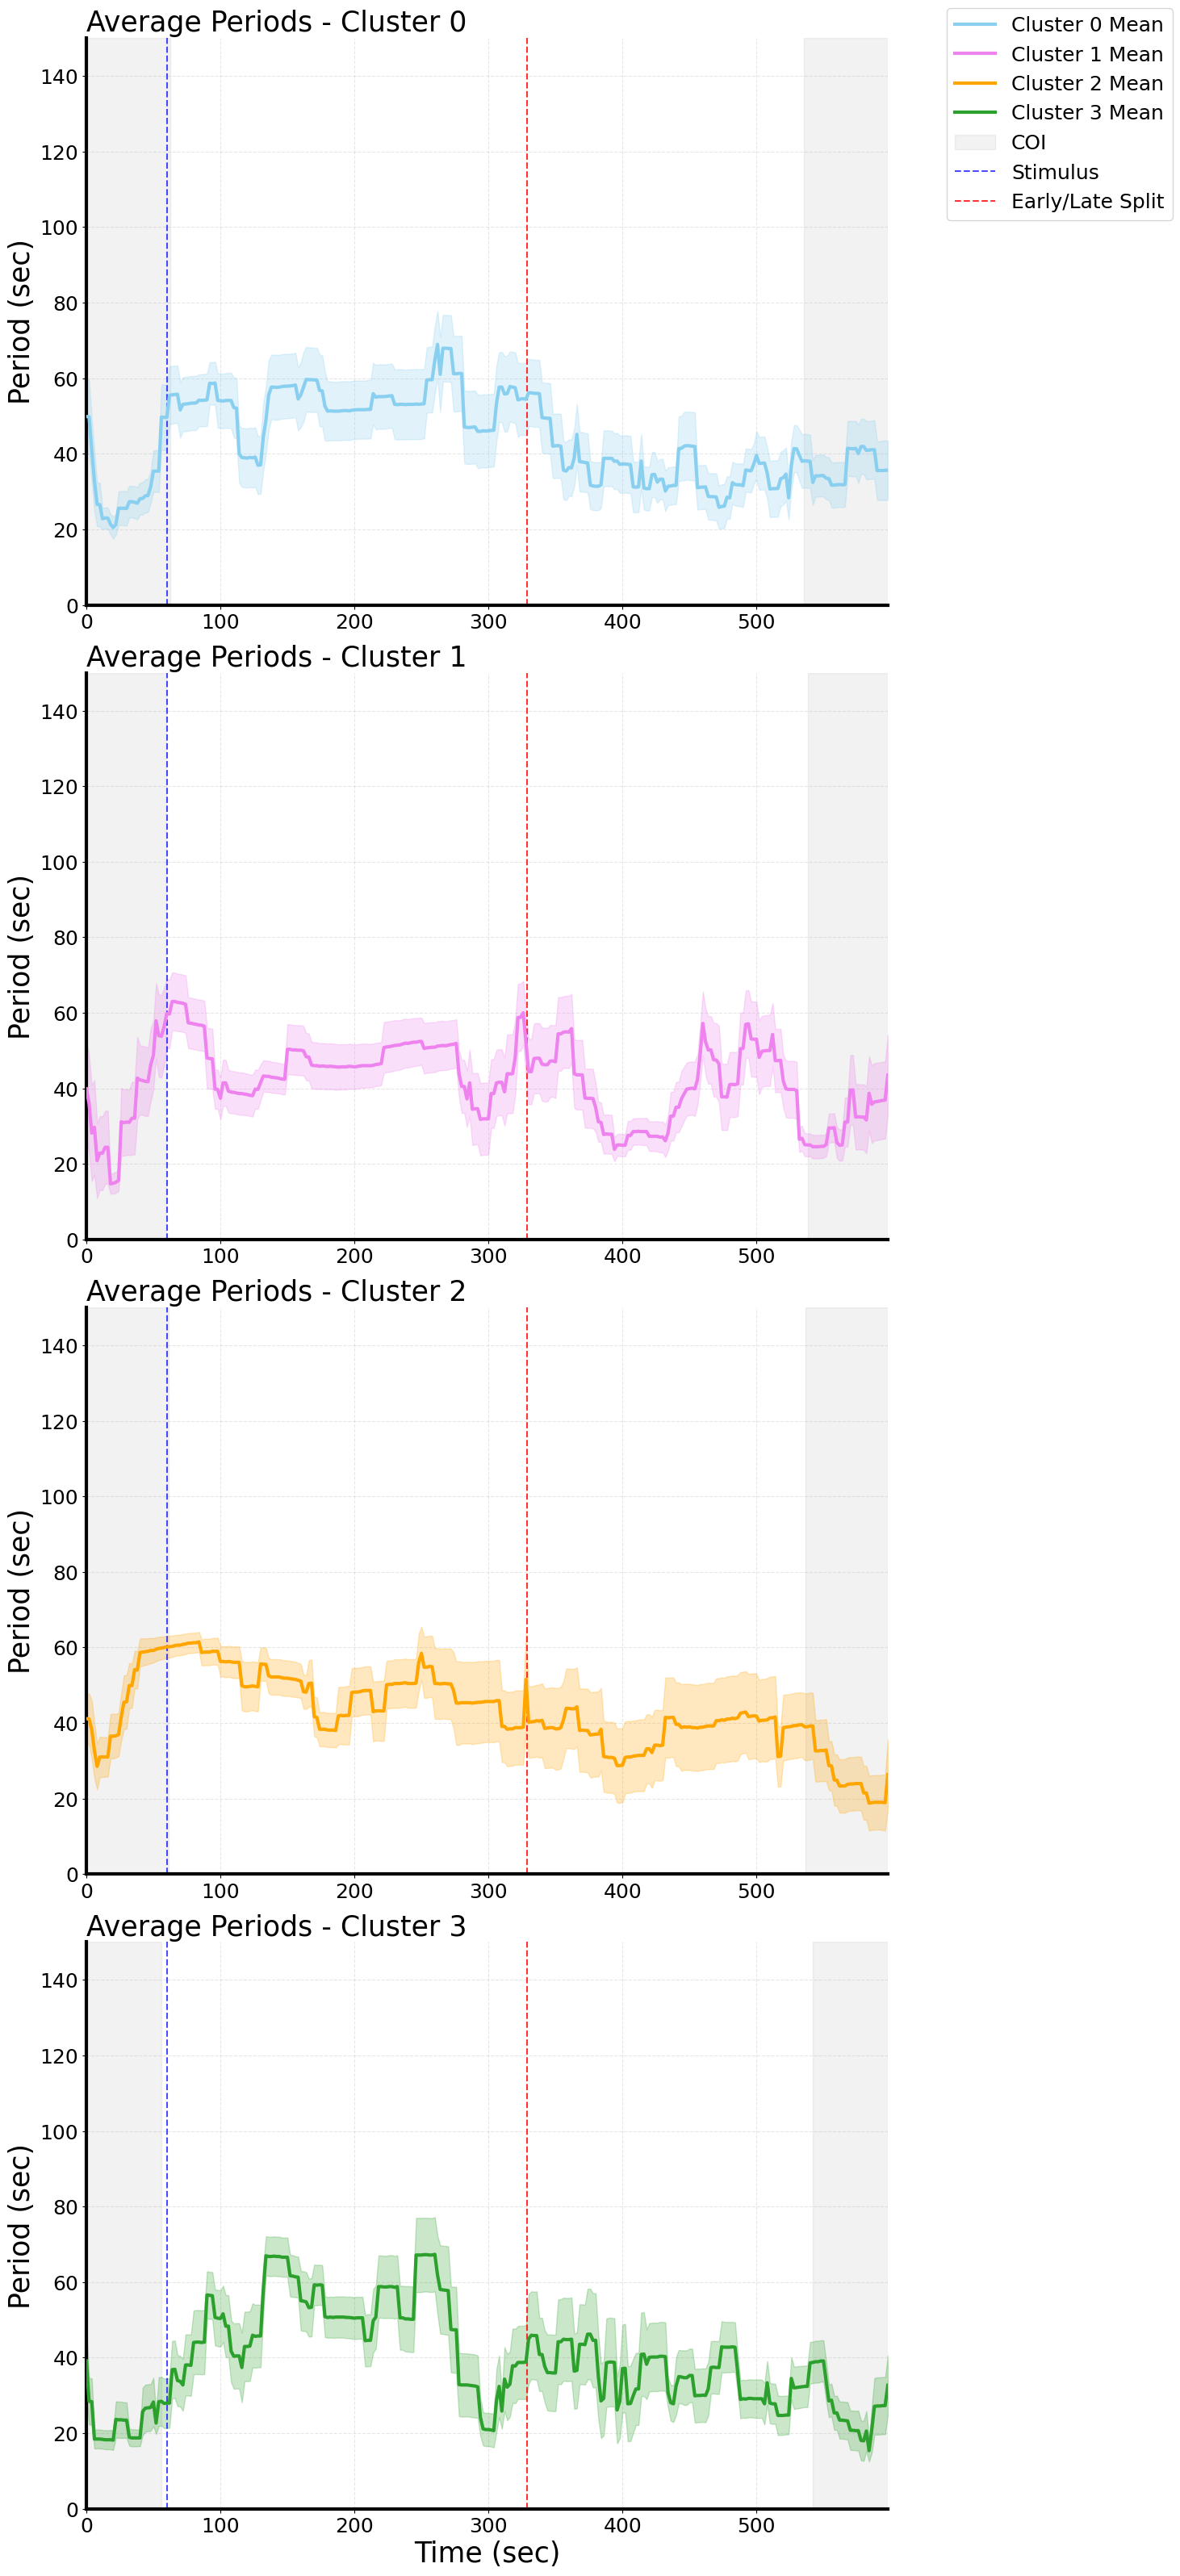

In [ ]:

print("Visualizing average period per cluster with Facet Plot and individualized COI...")

# Helper function to get canonical cell ID
def get_canonical_cell_id(cell_id_str):
    if not isinstance(cell_id_str, str):
        return str(cell_id_str)
    match = re.search(r'(\d+)', cell_id_str)
    return match.group(1) if match else cell_id_str

# Check availability
if 'df_combined_all_features' not in globals() or 'umap_df_pipeline' not in globals() or globals()['df_combined_all_features'].empty or globals()['umap_df_pipeline'].empty:
    missing_data = []
    if 'df_combined_all_features' not in globals() or globals()['df_combined_all_features'].empty:
        missing_data.append("df_combined_all_features (produced by cell 73abb262)")
    if 'umap_df_pipeline' not in globals() or globals()['umap_df_pipeline'].empty:
        missing_data.append("umap_df_pipeline (produced by cell 4aecaa7e)")
    print(f"Error: The following necessary DataFrames are not available or are empty: {', '.join(missing_data)}.")
    print("Please ensure you run cells 73abb262 (Data Loading) and 4aecaa7e (Pipeline) first.")
else:
    # Get global aesthetic parameters
    t_fs = globals().get('title_font_size_global', 20)
    l_fs = globals().get('label_font_size_global', 20)
    tk_fs = globals().get('tick_font_size_global', 15)
    ax_lw = globals().get('axis_line_width_global', 2)
    leg_fs = globals().get('legend_label_font_size_global', 18)

    time_col = 'time'
    stimulus_onset = globals().get('stimulus_onset_time_global', 60)
    split_time = globals().get('post_stimulus_split_time_global', 172)
    total_duration = df_combined_all_features[time_col].max()

    # Color map synchronized with UMAP (0: Light Blue, 1: Violet, 2: Orange, 3: Green)
    c_map = {
        0: '#89CFF0',  # Light Blue
        1: '#EE82EE',  # Violet
        2: '#FFA500',   # Orange
        3: '#2ca02c'    # Green for Cluster 3
    }

    # Prepare Data
    periods_cols = [col for col in df_combined_all_features.columns if col.endswith('_periods')]
    df_periods_melted = df_combined_all_features.melt(id_vars=[time_col], value_vars=periods_cols, var_name='cell_id', value_name='periods_value')
    df_periods_melted['cell_id'] = df_periods_melted['cell_id'].str.replace('_periods', '')

    # Canonical Merge
    df_periods_melted['canonical_cell_id'] = df_periods_melted['cell_id'].apply(get_canonical_cell_id)
    umap_temp = umap_df_pipeline.copy()
    umap_temp['canonical_cell_id'] = umap_temp['cell_id'].apply(get_canonical_cell_id)

    df_data = pd.merge(df_periods_melted, umap_temp[['canonical_cell_id', 'hierarchical_cluster']], on='canonical_cell_id', how='left').dropna(subset=['hierarchical_cluster'])
    df_data['hierarchical_cluster'] = df_data['hierarchical_cluster'].astype(int)

    # Aggregation
    mean_stats = df_data.groupby([time_col, 'hierarchical_cluster'])['periods_value'].agg(['mean', 'sem']).reset_index()

    # Facet Plot Setup - Increased height per cluster and width for consistent figure size
    clusters = sorted(df_data['hierarchical_cluster'].unique())
    fig, axes = plt.subplots(len(clusters), 1, figsize=(14, 8 * len(clusters)), sharex=True, sharey=False)
    if len(clusters) == 1: axes = [axes]

    # Lists to collect handles and labels for the single figure legend
    cluster_mean_handles = []
    cluster_mean_labels = []

    # Create proxy artists for common elements that appear on multiple subplots
    coi_proxy = mpatches.Patch(color='gray', alpha=0.1, label='COI')
    stimulus_proxy = plt.Line2D([0], [0], color='blue', linestyle='--', alpha=0.7, label='Stimulus')
    split_proxy = plt.Line2D([0], [0], color='red', linestyle='--', alpha=0.8, label='Early/Late Split')

    for i, cluster_id in enumerate(clusters):
        ax = axes[i]
        subset = mean_stats[mean_stats['hierarchical_cluster'] == cluster_id]
        color = c_map.get(cluster_id, 'gray')

        # COI LOGIC
        cells_in_cluster = umap_temp[umap_temp['hierarchical_cluster'] == cluster_id]['cell_id'].values
        cluster_period_cols_for_coi = [f"{c}_periods" for c in cells_in_cluster if f"{c}_periods" in df_combined_all_features.columns]

        if cluster_period_cols_for_coi:
            avg_period_series = df_combined_all_features[cluster_period_cols_for_coi].mean(axis=1).values
            representative_coi_period = np.nanmean(avg_period_series)
            if np.isnan(representative_coi_period) or representative_coi_period == 0:
                representative_coi_period = 8
            coi_width_seconds = 1.43 * representative_coi_period
            ax.axvspan(0, coi_width_seconds, color='gray', alpha=0.1) # No label here, will use proxy
            ax.axvspan(total_duration - coi_width_seconds, total_duration, color='gray', alpha=0.1)

        # Main Plot (Mean + SEM) and collect handle
        line, = ax.plot(subset[time_col], subset['mean'], label=f'Cluster {cluster_id}', color=color, linewidth=ax_lw, zorder=3)
        cluster_mean_handles.append(line)
        cluster_mean_labels.append(f'Cluster {cluster_id} Mean')
        ax.fill_between(subset[time_col], subset['mean'] - subset['sem'], subset['mean'] + subset['sem'], color=color, alpha=0.25, zorder=2)

        # Vertical Lines
        ax.axvline(stimulus_onset, color='blue', linestyle='--', alpha=0.7)
        if split_time and not np.isnan(split_time):
            ax.axvline(split_time, color='red', linestyle='--', alpha=0.8)

        # Refined scientific presentation
        ax.set_ylim(0, 150)
        ax.set_xlim(0, total_duration)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(ax_lw)
        ax.spines['bottom'].set_linewidth(ax_lw)

        ax.set_ylabel('Period (sec)', fontsize=l_fs)
        ax.set_title(f'Average Periods - Cluster {cluster_id}', fontsize=t_fs, loc='left')
        ax.grid(True, linestyle='--', alpha=0.3, zorder=0)

        # Ticks
        ax.tick_params(axis='both', labelsize=tk_fs)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')

    axes[-1].set_xlabel('Time (sec)', fontsize=l_fs)

    # Combine all handles and labels for the single figure legend
    final_legend_handles = cluster_mean_handles + [coi_proxy, stimulus_proxy, split_proxy]
    final_legend_labels = cluster_mean_labels + ['COI', 'Stimulus', 'Early/Late Split']

    # Create a single legend for the entire figure
    fig.legend(final_legend_handles, final_legend_labels, loc='upper right', bbox_to_anchor=(1.05, 1),
               fontsize=leg_fs, frameon=True, facecolor='white', framealpha=0.8)

    # Adjust tight_layout to make more space for the legend on the right
    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.show()

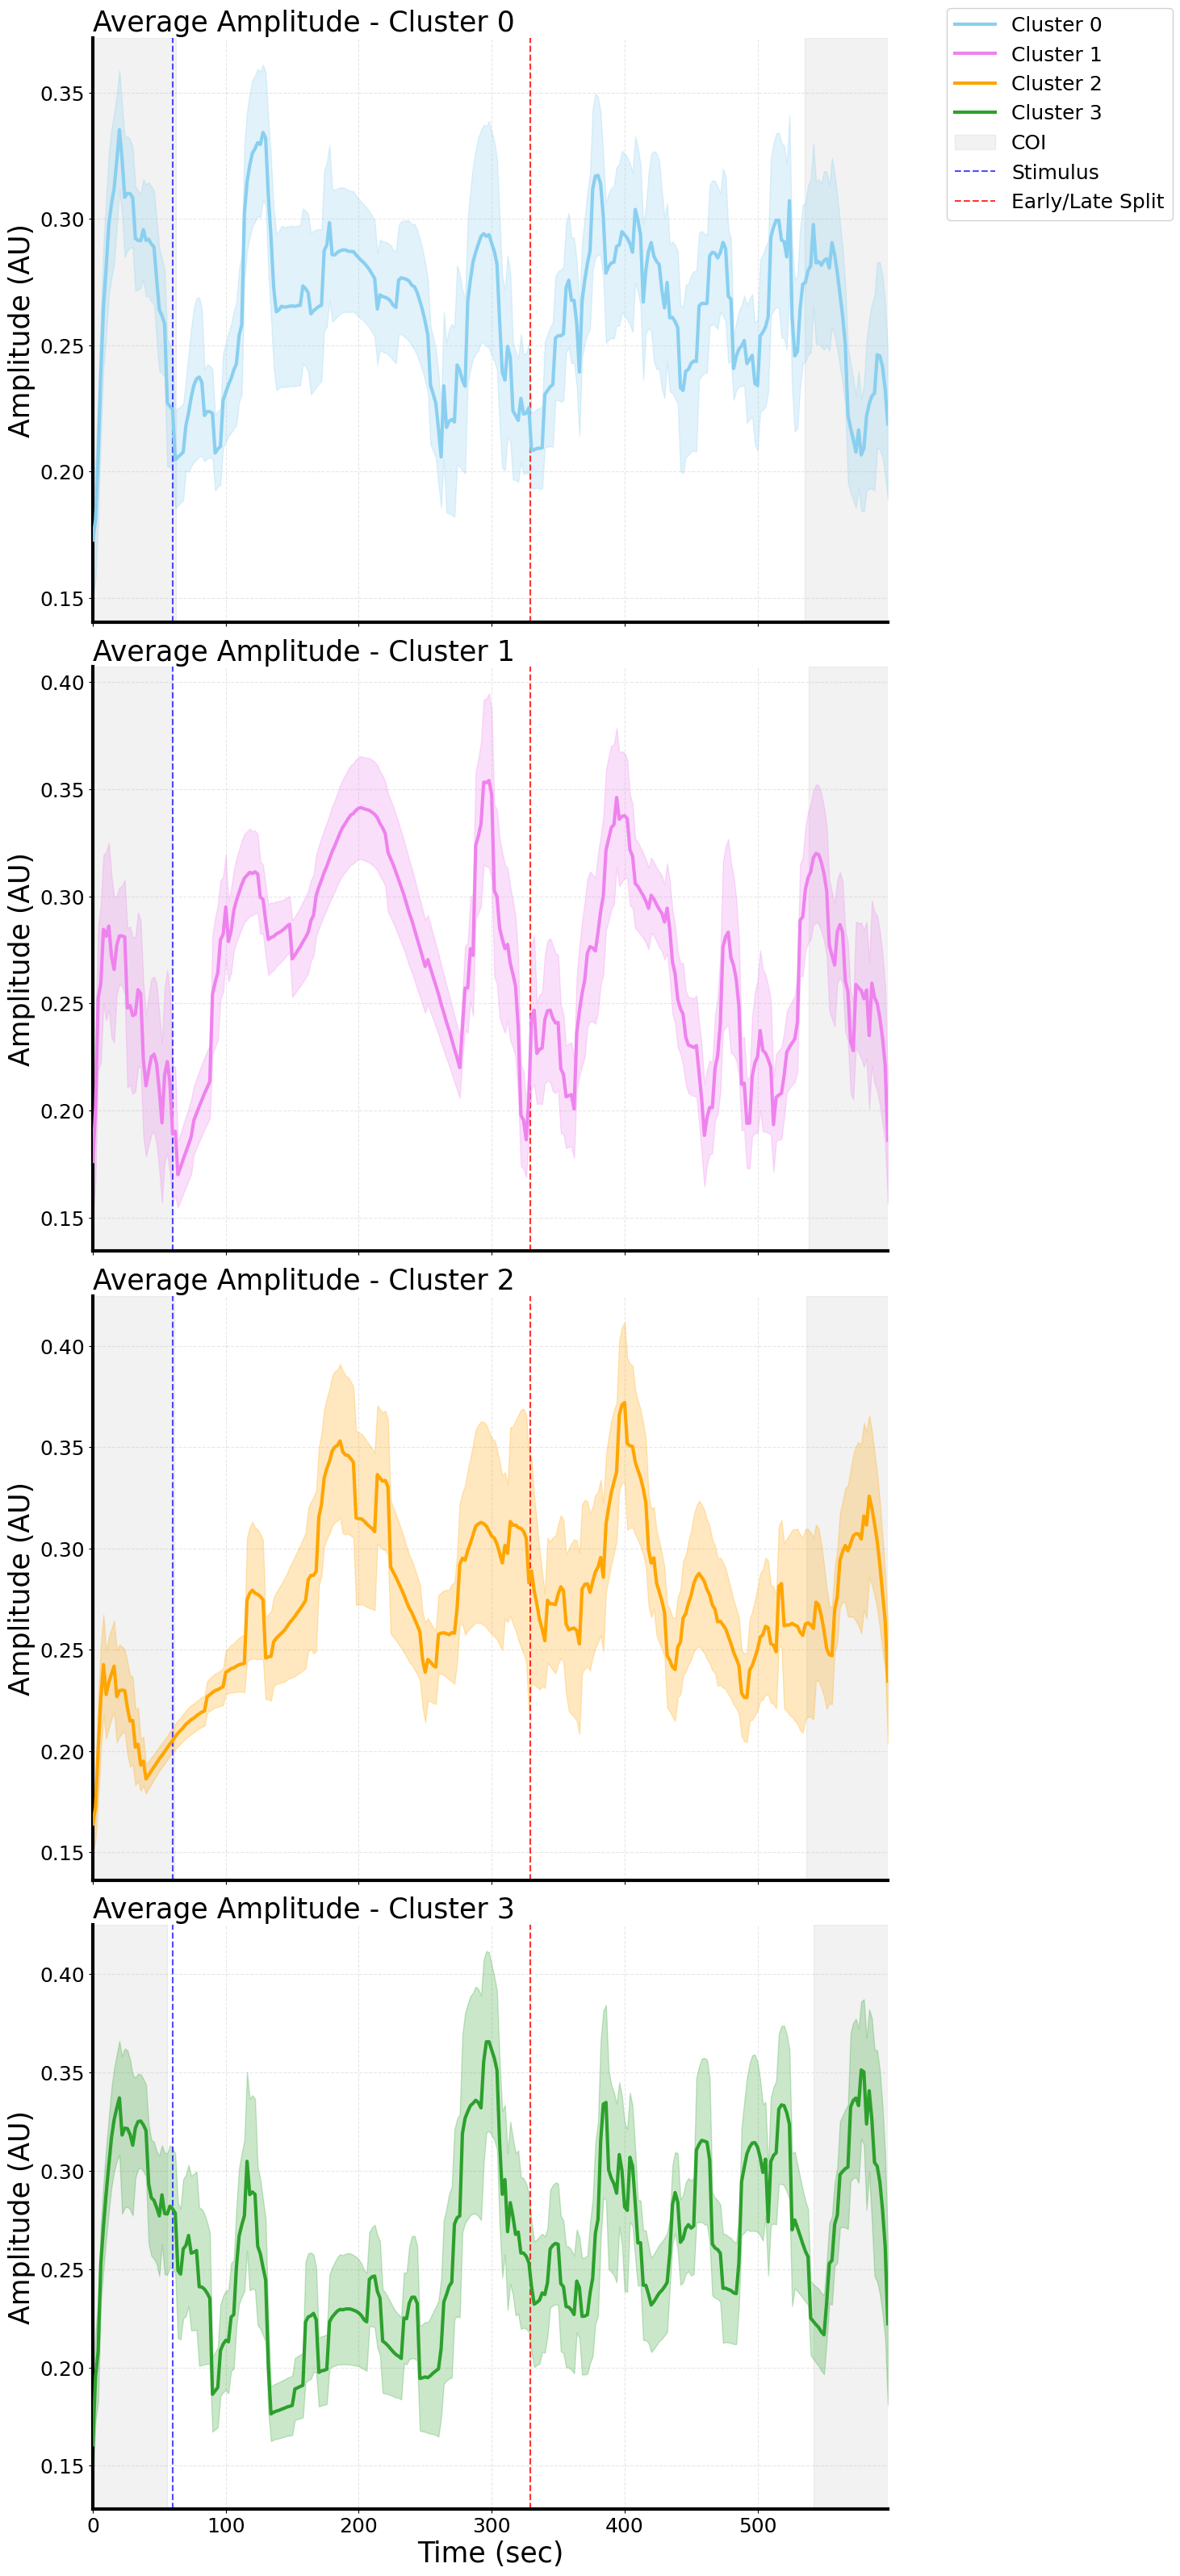

In [ ]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.patches as mpatches

# Helper function to get canonical cell ID
def get_canonical_id(s):
    m = re.search(r'(\d+)', str(s))
    return m.group(1) if m else str(s)

if 'df_combined_all_features' not in globals() or 'umap_df_pipeline' not in globals():
    print("Error: Necessary DataFrames (df_combined_all_features or umap_df_pipeline) not found.")
else:
    # 1. Retrieve Global Aesthetics
    t_fs = globals().get('title_font_size_global', 25)
    l_fs = globals().get('label_font_size_global', 25)
    tk_fs = globals().get('tick_font_size_global', 18)
    ax_lw = globals().get('axis_line_width_global', 3)
    leg_fs = globals().get('legend_label_font_size_global', 18)

    time_col = 'time'
    stimulus_onset = globals().get('stimulus_onset_time_global', 60)
    split_time = globals().get('post_stimulus_split_time_global', 143.5)
    total_duration = df_combined_all_features[time_col].max()

    # Color map synchronized with UMAP labels
    c_map = {0: '#89CFF0', 1: '#EE82EE', 2: '#FFA500', 3: '#2ca02c'}

    # 2. Prepare Amplitude Data
    amplitude_cols = [col for col in df_combined_all_features.columns if col.endswith('_amplitude')]
    df_amp_melted = df_combined_all_features.melt(id_vars=[time_col], value_vars=amplitude_cols, var_name='cell_id', value_name='amplitude_value')
    df_amp_melted['cell_id'] = df_amp_melted['cell_id'].str.replace('_amplitude', '')
    df_amp_melted['canonical_id'] = df_amp_melted['cell_id'].apply(get_canonical_id)

    # 3. Merge with Clusters
    umap_temp = umap_df_pipeline.copy()
    umap_temp['canonical_id'] = umap_temp['cell_id'].apply(get_canonical_id)
    df_plot_amp = pd.merge(df_amp_melted, umap_temp[['canonical_id', 'hierarchical_cluster']], on='canonical_id', how='left').dropna(subset=['hierarchical_cluster'])
    df_plot_amp['hierarchical_cluster'] = df_plot_amp['hierarchical_cluster'].astype(int)

    # 4. Aggregate Statistics
    mean_amp_stats = df_plot_amp.groupby([time_col, 'hierarchical_cluster'])['amplitude_value'].agg(['mean', 'sem']).reset_index()
    clusters = sorted(df_plot_amp['hierarchical_cluster'].unique())

    # 5. Plotting
    fig, axes = plt.subplots(len(clusters), 1, figsize=(14, 8 * len(clusters)), sharex=True)
    if len(clusters) == 1: axes = [axes]

    cluster_handles = []
    cluster_labels = []

    # Common elements proxy artists
    coi_proxy = mpatches.Patch(color='gray', alpha=0.1, label='COI')
    stim_proxy = plt.Line2D([0], [0], color='blue', linestyle='--', alpha=0.7, label='Stimulus')
    split_proxy = plt.Line2D([0], [0], color='red', linestyle='--', alpha=0.8, label='Early/Late Split')

    for i, cluster_id in enumerate(clusters):
        ax = axes[i]
        subset = mean_amp_stats[mean_amp_stats['hierarchical_cluster'] == cluster_id]
        color = c_map.get(cluster_id, 'gray')

        # COI Logic per Cluster (based on average periods)
        cells_in_clus = umap_temp[umap_temp['hierarchical_cluster'] == cluster_id]['cell_id'].values
        period_cols = [f"{c}_periods" for c in cells_in_clus if f"{c}_periods" in df_combined_all_features.columns]
        if period_cols:
            avg_p = df_combined_all_features[period_cols].mean(axis=1).mean()
            coi_val = 1.43 * avg_p
            ax.axvspan(0, coi_val, color='gray', alpha=0.1)
            ax.axvspan(total_duration - coi_val, total_duration, color='gray', alpha=0.1)

        # Mean + SEM Line
        line, = ax.plot(subset[time_col], subset['mean'], color=color, linewidth=ax_lw, zorder=3)
        ax.fill_between(subset[time_col], subset['mean'] - subset['sem'], subset['mean'] + subset['sem'], color=color, alpha=0.25, zorder=2)

        cluster_handles.append(line)
        cluster_labels.append(f'Cluster {cluster_id}')

        # Vertical Markers
        ax.axvline(stimulus_onset, color='blue', linestyle='--', alpha=0.7)
        if not np.isnan(split_time): ax.axvline(split_time, color='red', linestyle='--', alpha=0.8)

        # Standard Scientific Styling
        ax.set_xlim(0, total_duration)
        # ax.set_ylim(0, 3.5) # Reverted to auto-scale to handle clusters with different magnitudes
        ax.set_ylabel('Amplitude (AU)', fontsize=l_fs)
        ax.set_title(f'Average Amplitude - Cluster {cluster_id}', fontsize=t_fs, loc='left')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.tick_params(axis='both', labelsize=tk_fs)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(ax_lw)
        ax.spines['bottom'].set_linewidth(ax_lw)

    axes[-1].set_xlabel('Time (sec)', fontsize=l_fs)

    # Unified Legend
    final_h = cluster_handles + [coi_proxy, stim_proxy, split_proxy]
    final_l = cluster_labels + ['COI', 'Stimulus', 'Early/Late Split']
    fig.legend(final_h, final_l, loc='upper right', bbox_to_anchor=(1.05, 1), fontsize=leg_fs, frameon=True, facecolor='white', framealpha=0.9)

    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.show()

##Visualization of Temporal Dynamics with Violin Plots

This block generates violin plots grouped by cluster to visualize the evolution of **Wavelet Power** (COI-filtered data) and **Period** (complete segments). Annotations of statistical significance are included, comparing each post-stimulus segment with its respective baseline.

Generando visualizaciones homogenizadas con rigor estadístico sincronizado (N>=6 para pruebas)...


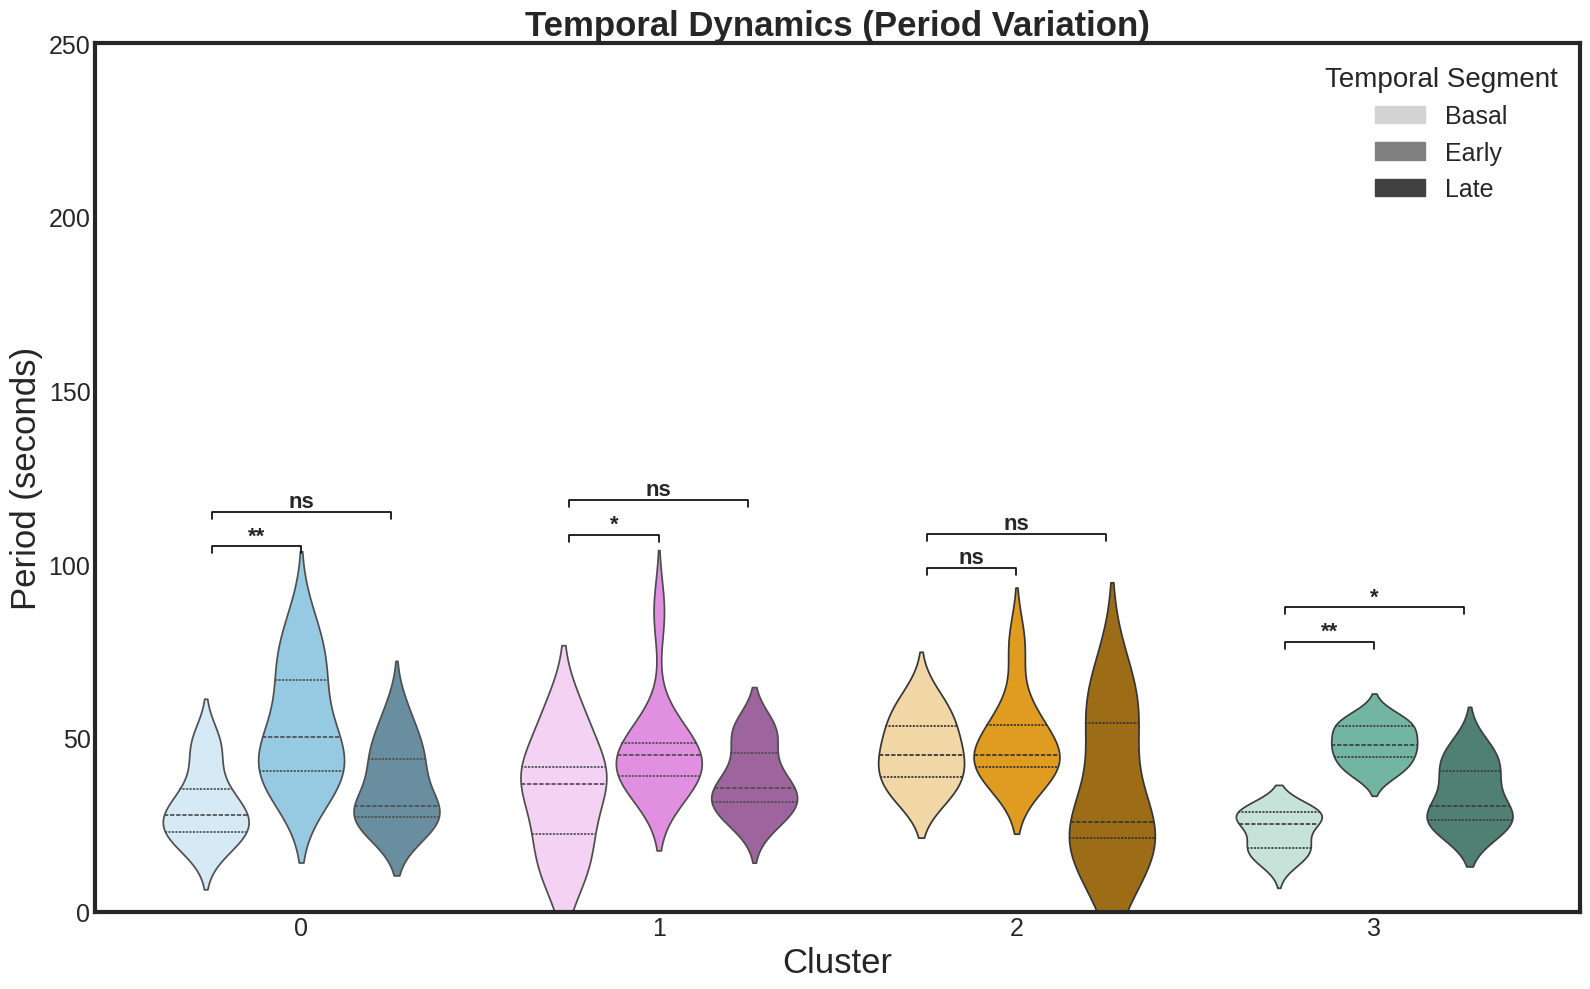

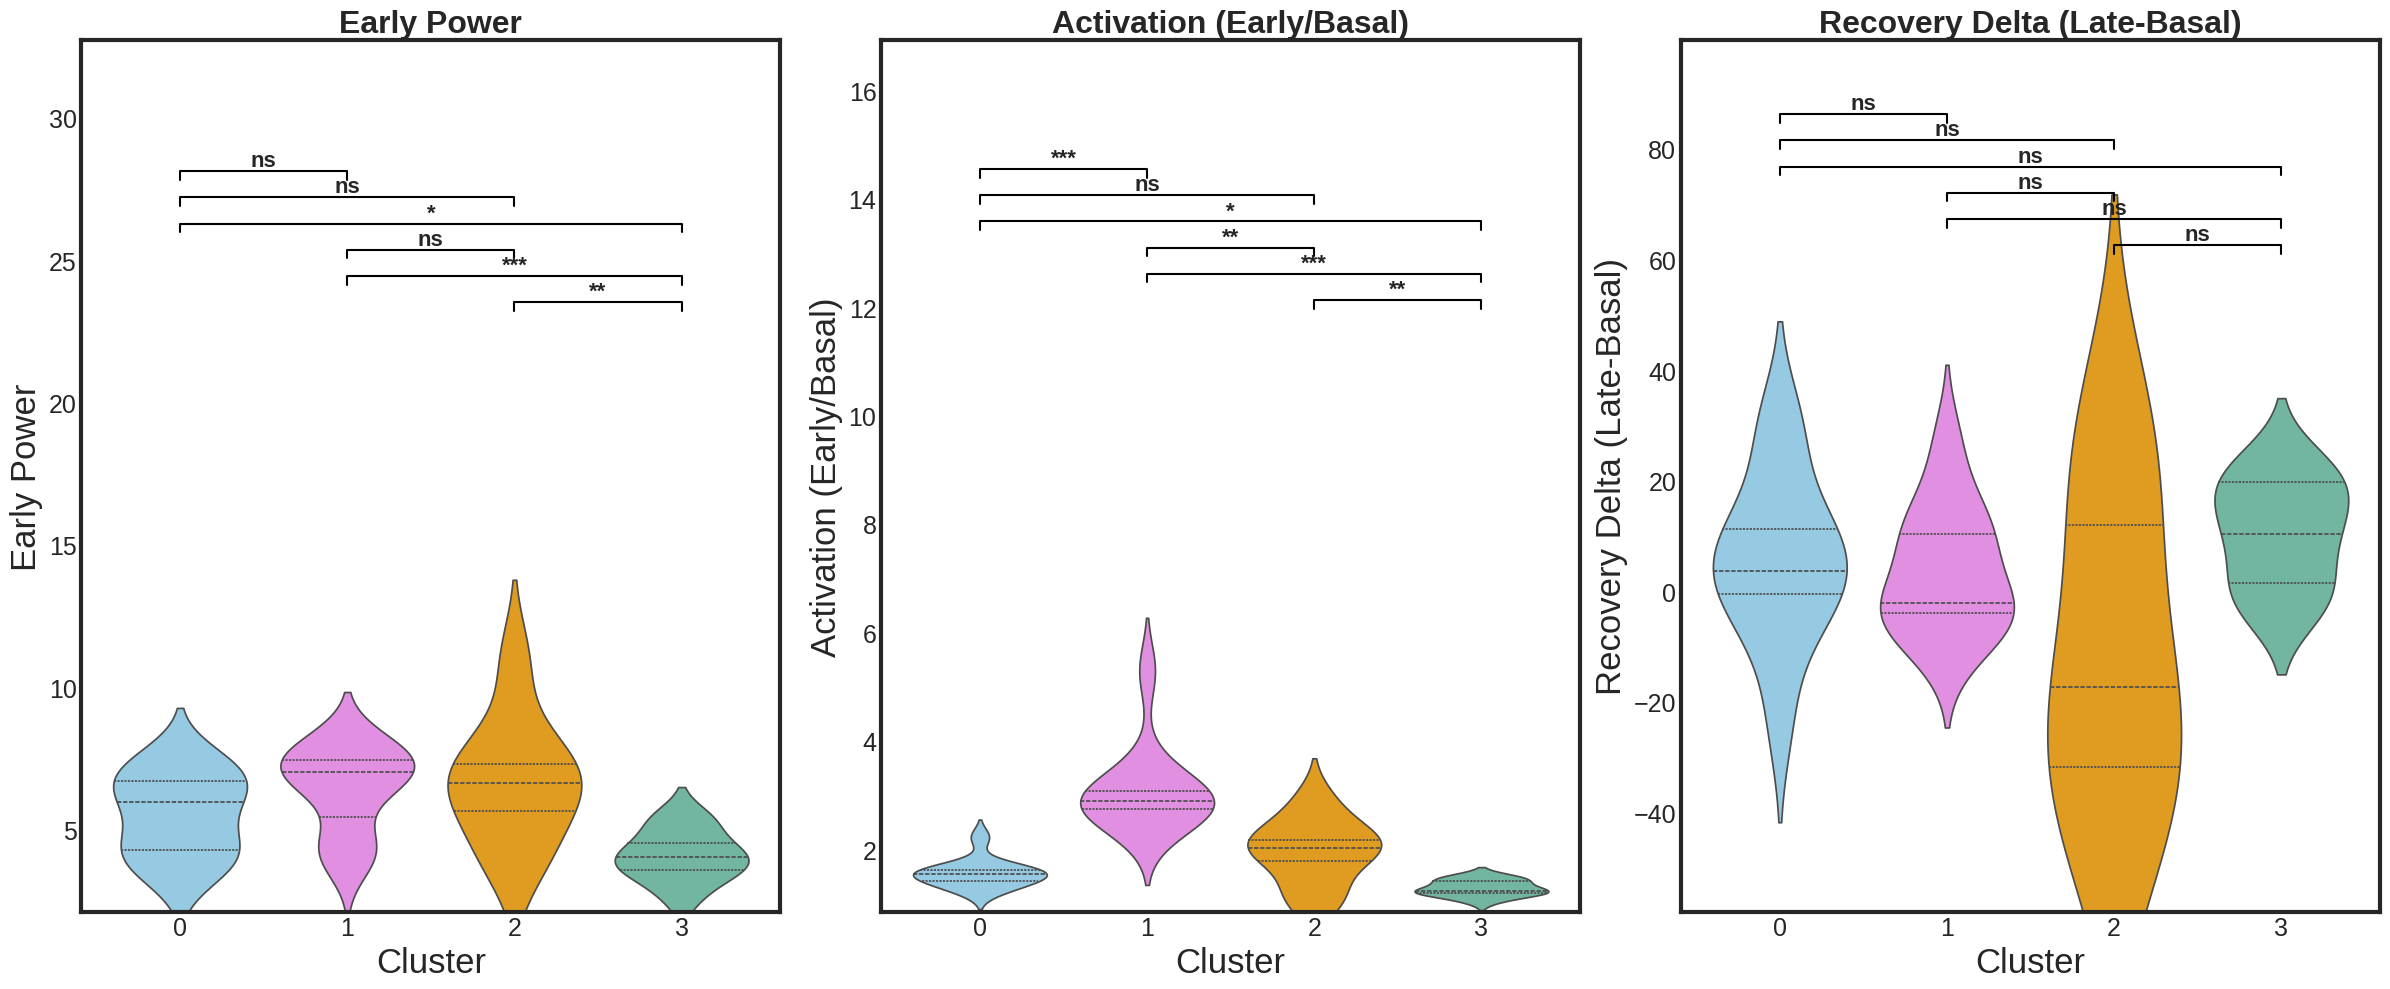

In [ ]:
print("Generating homogenized visualizations with synchronized statistical rigor (N>=6 for testing)...")

def get_canon(s):
    m = re.search(r'(\d+)', str(s))
    return m.group(1) if m else str(s)

# Retrieve global aesthetic parameters
t_fs = globals().get('title_font_size_global', 20)
l_fs = globals().get('label_font_size_global', 20)
tk_fs = globals().get('tick_font_size_global', 15)
ax_lw = globals().get('axis_line_width_global', 2)
leg_fs = globals().get('legend_label_font_size_global', 14)

if 'df_combined_all_features' in locals() and 'umap_df_pipeline' in locals():
    umap_map = umap_df_pipeline.copy()
    umap_map['canon_id'] = umap_map['cell_id'].apply(get_canon)
    cluster_dict = umap_map.set_index('canon_id')['hierarchical_cluster'].to_dict()

    stats_data = []
    time = df_combined_all_features['time'].values

    stim_onset_val = globals().get('stimulus_onset_time_global', 60)
    split_time_val = globals().get('post_stimulus_split_time_global', 172)

    stim = float(stim_onset_val) if stim_onset_val is not None else 60.0
    split = float(split_time_val) if split_time_val is not None else 172.0

    power_cols = [c for c in df_combined_all_features.columns if c.endswith('_power')]
    for col in power_cols:
        base = col.replace('_power', '')
        canon = get_canon(base)
        clus = cluster_dict.get(canon)

        if clus is not None:
            p_vals = df_combined_all_features[col].values
            per_col = f"{base}_periods"
            if per_col in df_combined_all_features.columns:
                per_vals = df_combined_all_features[per_col].values

                stats_data.append({
                    'cell_id': base,
                    'cluster': str(clus),
                    'Power_Early': np.nanmean(p_vals[(time >= stim) & (time < split)]),
                    'Period_Basal': np.nanmean(per_vals[time < stim]),
                    'Period_Early': np.nanmean(per_vals[(time >= stim) & (time < split)]),
                    'Period_Late': np.nanmean(per_vals[time >= split]),
                    'Activation_Ratio': np.nanmean(p_vals[(time >= stim) & (time < split)]) / np.nanmean(p_vals[time < stim]) if np.nanmean(p_vals[time < stim]) > 0 else np.nan,
                    'Recovery_Delta': np.nanmean(per_vals[time >= split]) - np.nanmean(per_vals[time < stim])
                })
    df_stats_ready = pd.DataFrame(stats_data)
else:
    df_stats_ready = pd.DataFrame()

if not df_stats_ready.empty:
    plt.style.use('seaborn-v0_8-white')

    # Annotation parameters
    fig1_ylim_top = 250
    fig1_anno_offset_base = 0.08
    fig1_anno_step_multiplier = 0.04

    fig2_y_scales = {'Power_Early': 2.0, 'Activation_Ratio': 2.2, 'Recovery_Delta': 2.0}
    fig2_anno_step_multiplier = 0.03

    def get_stars(p):
        return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

    cluster_color_map = {'0': '#89CFF0', '1': '#EE82EE', '2': '#FFA500', '3': '#66c2a5'}
    cluster_order = sorted(df_stats_ready['cluster'].unique(), key=lambda x: int(x))

    df_p_long = df_stats_ready.melt(id_vars=['cell_id', 'cluster'], value_vars=['Period_Basal', 'Period_Early', 'Period_Late'], var_name='Segment', value_name='Period')
    df_p_long['Segment'] = df_p_long['Segment'].str.replace('Period_', '')
    order_seg = ['Basal', 'Early', 'Late']

    # FIGURE 1: Temporal Dynamics
    plt.figure(figsize=(16, 10))
    ax1 = plt.gca()

    for i, clus_id in enumerate(cluster_order):
        rgb = mcolors.to_rgb(cluster_color_map.get(clus_id, 'gray'))
        clus_palette = [mcolors.to_hex(np.array(rgb) + (1 - np.array(rgb)) * 0.6), cluster_color_map.get(clus_id, 'gray'), mcolors.to_hex(np.array(rgb) * 0.7)]
        sns.violinplot(data=df_p_long[df_p_long['cluster'] == clus_id], x='cluster', y='Period', hue='Segment', hue_order=order_seg, palette=clus_palette, inner='quartile', ax=ax1, gap=0.1, legend=False)

    plt.title("Temporal Dynamics (Period Variation)", fontsize=t_fs, fontweight='bold')
    plt.ylabel("Period (seconds)", fontsize=l_fs)
    plt.xlabel("Cluster", fontsize=l_fs)
    ax1.tick_params(axis='both', labelsize=tk_fs)
    ax1.set_ylim(0, fig1_ylim_top)

    for spine in ax1.spines.values():
        spine.set_linewidth(ax_lw)

    plot_height_fig1 = ax1.get_ylim()[1]
    hue_offsets = [-0.25, 0, 0.25]
    for i, clus_id in enumerate(cluster_order):
        df_c = df_stats_ready[df_stats_ready['cluster'] == clus_id]
        local_max = df_p_long[df_p_long['cluster'] == clus_id]['Period'].max()
        for j, seg in enumerate(['Early', 'Late']):
            paired = df_c[['Period_Basal', f'Period_{seg}']].dropna()
            # Synchronized with Report: N >= 6 for Wilcoxon stars
            if len(paired) >= 6:
                _, p = wilcoxon(paired['Period_Basal'], paired[f'Period_{seg}'])
                x1, x2 = i + hue_offsets[0], i + hue_offsets[j+1]
                h = local_max + (plot_height_fig1 * (fig1_anno_offset_base + j * fig1_anno_step_multiplier))
                ax1.plot([x1, x1, x2, x2], [h, h + 2, h + 2, h], lw=1.2, c='black')
                ax1.text((x1 + x2) * 0.5, h + 2, get_stars(p), ha='center', va='bottom', fontsize=tk_fs-2, fontweight='bold')

    proxy_handles = [mpatches.Patch(color='#D3D3D3', label='Basal'), mpatches.Patch(color='#808080', label='Early'), mpatches.Patch(color='#404040', label='Late')]
    ax1.legend(handles=proxy_handles, title="Temporal Segment", loc='upper right', fontsize=leg_fs, title_fontsize=leg_fs+2)
    plt.tight_layout(); plt.show()

    # FIGURE 2: Metrics Comparison
    fig2, axes = plt.subplots(1, 3, figsize=(24, 10))
    metrics = [('Power_Early', 'Early Power'), ('Activation_Ratio', 'Activation (Early/Basal)'), ('Recovery_Delta', 'Recovery Delta (Late-Basal)')]

    for i, (col, name) in enumerate(metrics):
        ax = axes[i]
        sns.violinplot(data=df_stats_ready, x='cluster', y=col, order=cluster_order, palette=cluster_color_map, inner='quartile', ax=ax)
        ax.set_title(name, fontsize=t_fs - 2, fontweight='bold')
        ax.set_xlabel("Cluster", fontsize=l_fs)
        ax.set_ylabel(name, fontsize=l_fs)
        ax.tick_params(axis='both', labelsize=tk_fs)

        for spine in ax.spines.values():
            spine.set_linewidth(ax_lw)

        y_min, y_max = df_stats_ready[col].min(), df_stats_ready[col].max()
        ax.set_ylim(y_min - abs(y_min)*0.2, y_max + abs(y_max) * fig2_y_scales.get(col, 1.8))

        plot_height_fig2 = ax.get_ylim()[1] - ax.get_ylim()[0]
        groups = [df_stats_ready[df_stats_ready['cluster'] == c][col].dropna().values for c in cluster_order]

        # Synchronized with Report: Only plot t-test annotations if groups have N >= 6
        if len(cluster_order) > 1 and all(len(g) >= 6 for g in groups):
            pairs = list(combinations(range(len(cluster_order)), 2))
            y_start_annotation = ax.get_ylim()[1] * 0.85
            for idx, (idx1, idx2) in enumerate(pairs):
                _, p = ttest_ind(groups[idx1], groups[idx2])
                h = y_start_annotation - (plot_height_fig2 * (idx * fig2_anno_step_multiplier))
                ax.plot([idx1, idx1, idx2, idx2], [h, h + plot_height_fig2*0.01, h + plot_height_fig2*0.01, h], lw=1.5, c='black')
                ax.text((idx1 + idx2) * 0.5, h + plot_height_fig2*0.01, get_stars(p), ha='center', va='bottom', fontsize=tk_fs-2, fontweight='bold')

    plt.tight_layout(); plt.show()
else:
    print("No data to display. Please verify df_combined_all_features and umap_df_pipeline.")

##Statical Report Dynamics

In [ ]:
print("Generating Detailed Statistical Report...")

if 'df_stats_ready' in locals() and not df_stats_ready.empty:
    output = io.StringIO()
    sys.stdout = output

    print("========================================================")
    print("   STATISTICAL REPORT ON DYNAMICS AND RESPONSE (VIOLIN PLOTS) ")
    print(f"   Standard: N >= 5 for visualization | N >= 6 for testing")
    print("========================================================\n")

    clusters = sorted(df_stats_ready['cluster'].unique(), key=lambda x: int(x))

    # 1. INTRA-CLUSTER ANALYSIS (Basal vs Early/Late)
    print("--- 1. INTRA-CLUSTER TEMPORAL DYNAMICS (Wilcoxon Signed-Rank Tests) ---")
    for clus in clusters:
        df_c = df_stats_ready[df_stats_ready['cluster'] == clus]
        print(f"\n[Cluster {clus}] (Total N={len(df_c)})")

        tests = [
            ('Period_Basal', 'Period_Early', 'Period: Basal vs Early'),
            ('Period_Basal', 'Period_Late', 'Period: Basal vs Late')
        ]

        for c1, c2, label in tests:
            paired = df_c[[c1, c2]].dropna()
            n_paired = len(paired)
            if n_paired >= 6:
                _, p = wilcoxon(paired[c1], paired[c2])
                significance = 'Significant' if p < 0.05 else 'ns'
                print(f"  * {label}: N={n_paired}, p = {p:.6f} ({significance})")
            elif n_paired >= 5:
                print(f"  * {label}: N={n_paired}. Sufficient for visualization, but insufficient for testing (N < 6).")
            else:
                print(f"  * {label}: Insufficient data (N={n_paired}).")

    # 2. INTER-CLUSTER ANALYSIS (Comparison between groups)
    print("\n\n--- 2. INTER-CLUSTER COMPARISON (ANOVA + Post-hoc Tukey) ---")
    metrics = [
        ('Period_Early', 'Period in Early phase'),
        ('Activation_Ratio', 'Activation Ratio (Power E/B)'),
        ('Recovery_Delta', 'Recovery Delta (Period L-B)')
    ]

    for col, label in metrics:
        print(f"\nMetric: {label}")
        # Filter groups with N >= 6 for inter-cluster comparison consistency
        groups_data = []
        group_info = []

        for c in clusters:
            g = df_stats_ready[df_stats_ready['cluster'] == c][col].dropna()
            n_g = len(g)
            groups_data.append(g)
            group_info.append(f"C{c} (N={n_g})")

        print(f"  Group Sizes: {', '.join(group_info)}")

        if all(len(g) >= 6 for g in groups_data):
            f_stat, p_anova = f_oneway(*groups_data)
            print(f"  Inter-cluster ANOVA: F={f_stat:.4f}, p={p_anova:.6f}")

            if p_anova < 0.05:
                # Standard Tukey requires a flattened array and labels
                df_sub = df_stats_ready.dropna(subset=[col])
                tukey = pairwise_tukeyhsd(endog=df_sub[col], groups=df_sub['cluster'], alpha=0.05)
                print("  Post-hoc Tukey (Significant differences):")
                print(tukey)
        else:
            print("  Statistical testing skipped: One or more clusters have N < 6.")

    sys.stdout = sys.__stdout__
    report_str = output.getvalue()

    # Save to file
    with open('statistical_report.txt', 'w') as f:
        f.write(report_str)

    print(report_str)
    print("\nReport successfully saved to 'statistical_report.txt'.")
else:
    print("Error: 'df_stats_ready' not found. Please run the violin plots block first.")

Generating Detailed Statistical Report...


##Visualization of Phase Delta Box Plots by Cluster

##COI-Filtered Phase Delta Calculation
This block calculates the instantaneous phase difference between pairs of clusters using only data outside the COI (1.43×T).

In [ ]:
import numpy as np
import pandas as pd
import re
from itertools import combinations

def get_canon(s):
    m = re.search(r'(\d+)', str(s))
    return m.group(1) if m else str(s)

def is_outside_coi(t, p, total_duration):
    return (t > 1.43 * p) and (t < (total_duration - 1.43 * p))

if 'df_combined_all_features' in locals() and 'umap_df_pipeline' in locals():
    time_arr = df_combined_all_features['time'].values
    total_len = time_arr.max()
    umap_map = umap_df_pipeline.copy()
    umap_map['canon_id'] = umap_map['cell_id'].apply(get_canon)
    cluster_dict = umap_map.set_index('canon_id')['hierarchical_cluster'].to_dict()

    # 1. Extract COI-filtered phases
    phase_data_clean = {}
    for col in [c for c in df_combined_all_features.columns if c.endswith('_phase')]:
        base = col.replace('_phase','')
        canon = get_canon(base)
        clus = cluster_dict.get(canon)
        per_col = f"{base}_periods"

        if clus is not None and per_col in df_combined_all_features.columns:
            p_vals = df_combined_all_features[col].values
            per_vals = df_combined_all_features[per_col].values

            clean_phases = np.array([ph if is_outside_coi(t, p, total_len) else np.nan
                                    for t, p, ph in zip(time_arr, per_vals, p_vals)])

            if clus not in phase_data_clean: phase_data_clean[clus] = []
            phase_data_clean[clus].append(clean_phases)

    # 2. Complex average per cluster
    cluster_avg_phase = {}
    for clus, phase_list in phase_data_clean.items():
        complex_array = np.exp(1j * np.array(phase_list))
        avg_complex = np.nanmean(complex_array, axis=0)
        cluster_avg_phase[clus] = np.angle(avg_complex)

    # 3. Calculate Deltas between ALL dynamically detected pairs
    available_clusters = sorted(cluster_avg_phase.keys())
    pairs = list(combinations(available_clusters, 2))

    phase_diff_trajectories = []
    stim_onset = float(globals().get('stimulus_onset_time_global', 60) or 60.0)
    split_time = float(globals().get('post_stimulus_split_time_global', 172) or 172.0)

    for c1, c2 in pairs:
        diff = np.arctan2(np.sin(cluster_avg_phase[c1] - cluster_avg_phase[c2]),
                          np.cos(cluster_avg_phase[c1] - cluster_avg_phase[c2]))

        for i, t in enumerate(time_arr):
            if not np.isnan(diff[i]):
                seg = 'Basal' if t < stim_onset else ('Early' if t < split_time else 'Late')
                phase_diff_trajectories.append({
                    'Pair': f"{c1}-{c2}",
                    'Time': t,
                    'Segment': seg,
                    'Delta_Phi': diff[i]
                })

    df_phase_trajectories = pd.DataFrame(phase_diff_trajectories)
    if not df_phase_trajectories.empty:
        print(f"Trajectories calculated for detected pairs: {df_phase_trajectories['Pair'].unique()}")
    else:
        print("No trajectories generated (possibly outside COI or insufficient data).")
else:
    print("Error: DataFrames 'df_combined_all_features' or 'umap_df_pipeline' not found.")

##Violin Plots of Phase Trajectory and Significance
 Visualization of inter-cluster coupling using a biological scale of π and Wilcoxon/t-tests.

In [ ]:
if 'df_phase_trajectories' in locals() and not df_phase_trajectories.empty:
    unique_clusters = sorted(df_phase_trajectories['Pair'].str.split('-').apply(lambda x: [int(c) for c in x]).explode().unique())
    from itertools import combinations
    all_cluster_pairs = list(combinations(unique_clusters, 2))

    print("--- Diagnostic: Points per Segment ---")
    if not all_cluster_pairs:
        print("⚠️ Not enough clusters in df_phase_trajectories to form pairs.")
    else:
        for c1, c2 in all_cluster_pairs:
            pair_str = f"{c1}-{c2}"
            diag_pair = df_phase_trajectories[df_phase_trajectories['Pair'] == pair_str]
            if not diag_pair.empty:
                print(f"\n✅ Data found for Pair {pair_str}:")
                print(diag_pair['Segment'].value_counts())
            else:
                print(f"\n❌ No data for pair {pair_str} (filtered by COI).")

    if 'df_stats_ready' in locals() and not df_stats_ready.empty:
        print("\n--- Average Basal Periods & COI Limits ---")
        for cluster_id in unique_clusters:
            cluster_data = df_stats_ready[df_stats_ready['cluster'].astype(str) == str(cluster_id)]

            # Try different possible column names for basal period
            period_col = next((c for c in ['Period_Full_Basal', 'Period_Basal'] if c in cluster_data.columns), None)

            if period_col and not cluster_data.empty:
                avg_period = cluster_data[period_col].mean()
                print(f"Cluster {cluster_id}: {avg_period:.2f}s (COI Boundary: {1.43*avg_period:.2f}s)")
            else:
                print(f"⚠️ Cluster {cluster_id}: Basal period column not found in df_stats_ready.")

        onset = globals().get('stimulus_onset_time_global', 60)
        print(f"\nInfo: Stimulus Onset at {onset}s")
    else:
        print("\n⚠️ df_stats_ready not found. Please run the statistics blocks first.")
else:
    print("❌ df_phase_trajectories not found or empty. Please run the phase processing block (Z+5) first.")

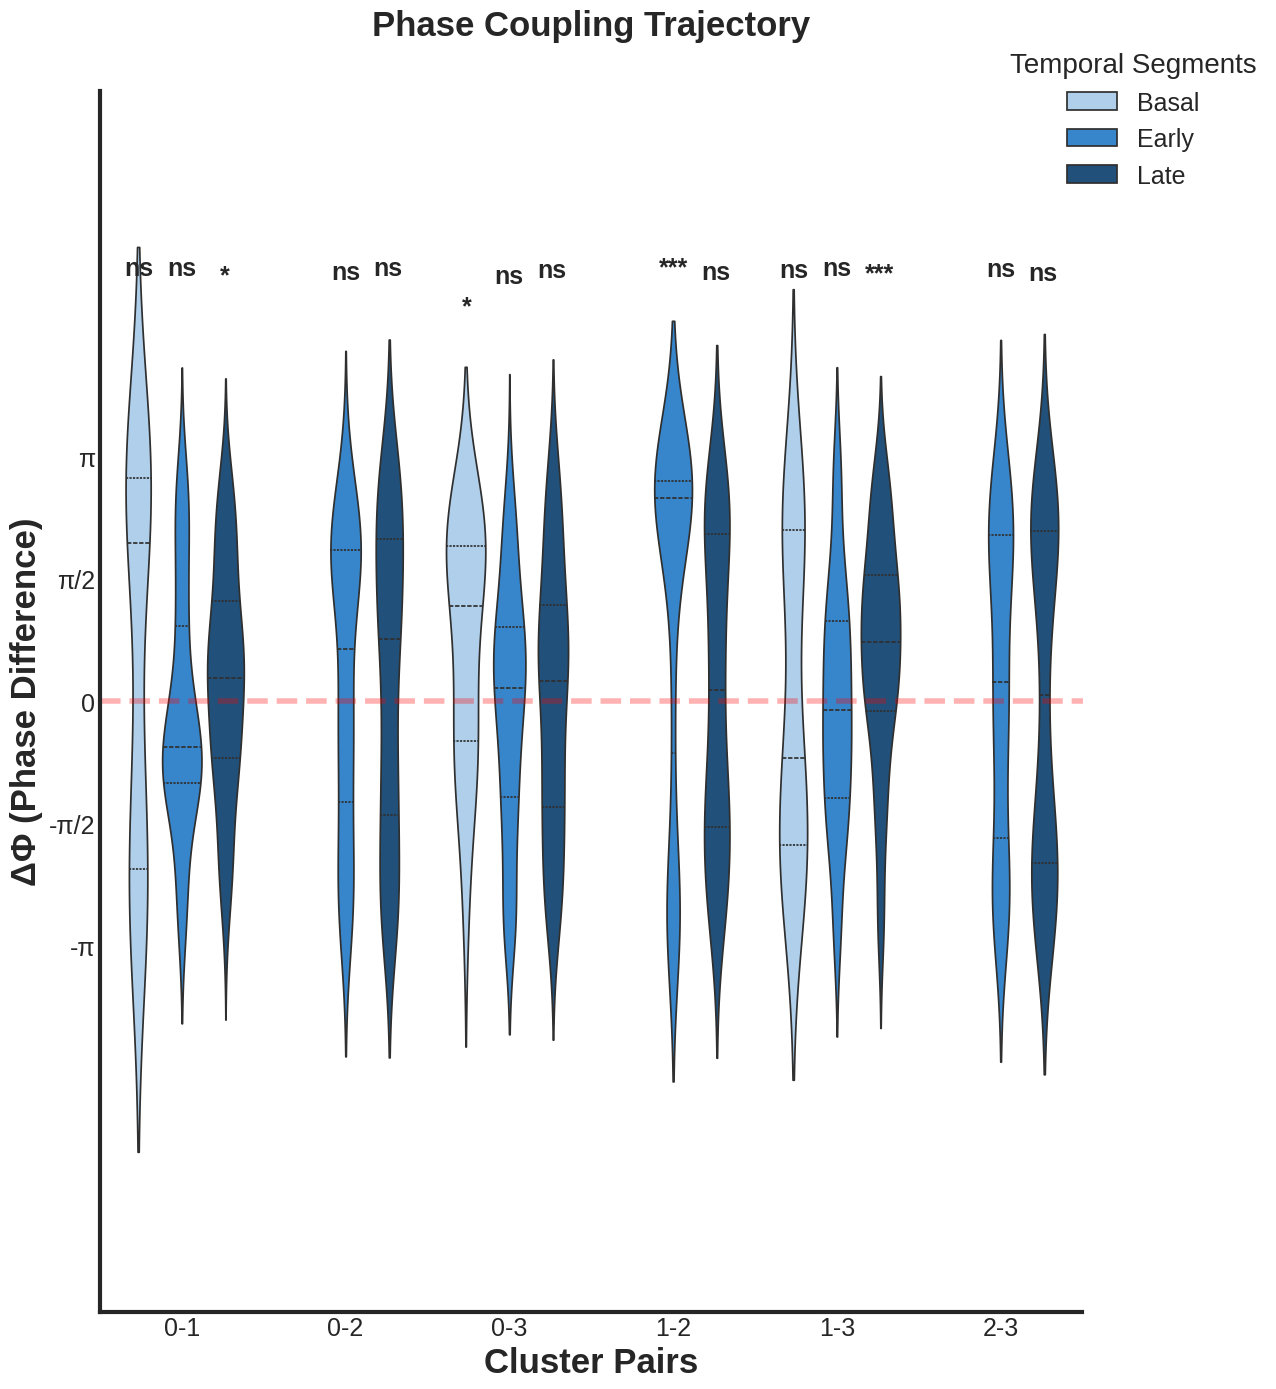

In [ ]:
df_to_plot_raw = globals().get('df_phase_trajectories')

if df_to_plot_raw is not None and not df_to_plot_raw.empty:
    # Define minimum threshold for solid visualization (N >= 8)
    MIN_N_VISUAL = 8

    # Filter groups with sufficient data to be representative
    counts = df_to_plot_raw.groupby(['Pair', 'Segment']).size().reset_index(name='count')
    valid_groups = counts[counts['count'] >= MIN_N_VISUAL]
    df_to_plot = df_to_plot_raw.merge(valid_groups[['Pair', 'Segment']], on=['Pair', 'Segment'], how='inner')

    # Retrieve global aesthetic parameters
    t_fs = globals().get('title_font_size_global', 25)
    l_fs = globals().get('label_font_size_global', 25)
    tk_fs = globals().get('tick_font_size_global', 18)
    ax_lw = globals().get('axis_line_width_global', 3)
    leg_title_fs = globals().get('legend_title_font_size_global', 20)
    leg_label_fs = globals().get('legend_label_font_size_global', 18)

    plt.figure(figsize=(20, 14))
    ax = plt.gca()

    # Color pool for pairs
    base_colors_pool = ['#1E88E5', '#D81B60', '#43A047', '#FFA000', '#7B1FA2']
    unique_pairs = sorted(df_to_plot['Pair'].unique())
    base_colors = {pair: base_colors_pool[i % len(base_colors_pool)] for i, pair in enumerate(unique_pairs)}

    order_seg = ['Basal', 'Early', 'Late']

    # Generate consistent palette per segment (Light, Base, Shadow)
    plot_palette = []
    for pair in unique_pairs:
        rgb = mcolors.to_rgb(base_colors[pair])
        plot_palette.append(mcolors.to_hex(np.array(rgb) + (1 - np.array(rgb)) * 0.6))
        plot_palette.append(base_colors[pair])
        plot_palette.append(mcolors.to_hex(np.array(rgb) * 0.6))

    sns.violinplot(data=df_to_plot, x='Pair', y='Delta_Phi', hue='Segment', hue_order=order_seg,
                   palette=plot_palette, inner='quartile', ax=ax, gap=0.1, width=0.8)

    # Axis formatting in units of Pi
    ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_yticklabels(['-π', '-π/2', '0', 'π/2', 'π'], fontsize=tk_fs)
    ax.tick_params(axis='x', labelsize=tk_fs)
    ax.tick_params(axis='y', labelsize=tk_fs)
    ax.axhline(0, color='red', linestyle='--', alpha=0.3, linewidth=ax_lw + 1)

    def get_stars(p): return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

    # Statistical Annotation Logic
    y_min_lim, y_max_lim = -np.pi * 2.5, np.pi * 2.5
    ax.set_ylim(y_min_lim, y_max_lim)
    y_range = y_max_lim - y_min_lim
    star_y_offset_factor = 0.15

    for i, pair in enumerate(unique_pairs):
        df_p = df_to_plot[df_to_plot['Pair'] == pair]
        offsets = [-0.26, 0, 0.26]
        for j, seg in enumerate(order_seg):
            vals = df_p[df_p['Segment'] == seg]['Delta_Phi'].dropna().values
            if len(vals) >= 6: # Standard requirement for Wilcoxon
                _, p = wilcoxon(vals)
                y_pos_data_max = vals.max() if vals.size > 0 else 0
                y_pos = y_pos_data_max + (y_range * star_y_offset_factor)
                y_pos = min(y_pos, y_max_lim * 0.9)
                ax.text(i + offsets[j], y_pos, get_stars(p), ha='center', fontweight='bold', fontsize=tk_fs)
            elif len(vals) == 5:
                # N=5 allows violin visualization but no ns reporting for rigor
                pass

    ax.set_ylabel('ΔΦ (Phase Difference)', fontweight='bold', fontsize=l_fs)
    ax.set_xlabel('Cluster Pairs', fontweight='bold', fontsize=l_fs)
    ax.set_title("Phase Coupling Trajectory", fontsize=t_fs, fontweight='bold', pad=40)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(ax_lw)
    ax.spines['bottom'].set_linewidth(ax_lw)

    plt.legend(title="Temporal Segments", loc='upper right',
               fontsize=leg_label_fs, title_fontsize=leg_title_fs, bbox_to_anchor=(1.2, 1.05))

    plt.tight_layout(rect=[0, 0, 0.7, 1])
    plt.show()
else:
    print("Error: No data found for phase trajectories.")

##Statical Report Phase Trajectory

In [ ]:
# Redirect output to capture it for the report
output = io.StringIO()
sys.stdout = output

print("========================================================")
print("   STATISTICAL REPORT: PHASE DELTA ANALYSIS (vs 0)")
print("   Criteria: Visualization N >= 5 | Stats N >= 6")
print("========================================================\n")

df_phase_trajectories = globals().get('df_phase_trajectories')

if df_phase_trajectories is None or df_phase_trajectories.empty:
    print("Error: 'df_phase_trajectories' not found. Please ensure block Z+5 is executed first.")
else:
    unique_pairs = sorted(df_phase_trajectories['Pair'].unique())
    segments = ['Basal', 'Early', 'Late']

    print("--- One-Sample Wilcoxon Test (Median vs 0) for Phase Delta ---")
    print("(Determines if Delta_Phi is significantly different from zero)\n")

    for pair in unique_pairs:
        print(f"Pair: {pair}")
        for seg in segments:
            data = df_phase_trajectories[(df_phase_trajectories['Pair'] == pair) &
                                         (df_phase_trajectories['Segment'] == seg)]['Delta_Phi'].dropna().values

            n_obs = len(data)
            if n_obs >= 6:
                try:
                    stat, p = wilcoxon(data, alternative='two-sided')
                    significance = 'Significant' if p < 0.05 else 'Not Significant'
                    print(f"  - Segment {seg}: N = {n_obs}, p = {p:.6f} ({significance})")
                except ValueError:
                    print(f"  - Segment {seg}: N = {n_obs}, Wilcoxon failed (all values tied).")
            elif n_obs >= 5:
                print(f"  - Segment {seg}: N = {n_obs}. Sufficient for visualization, but insufficient for statistical testing (N < 6).")
            else:
                print(f"  - Segment {seg}: Insufficient data (N = {n_obs}). Segment excluded.")
        print("")

sys.stdout = sys.__stdout__
report_str = output.getvalue()

with open('statistical_report_Phase_Delta_Wilcoxon_Mio.txt', 'w') as f:
    f.write(report_str)

print(report_str)
print("\nPhase comparison report updated and saved.")

##Phase Coherence (R)

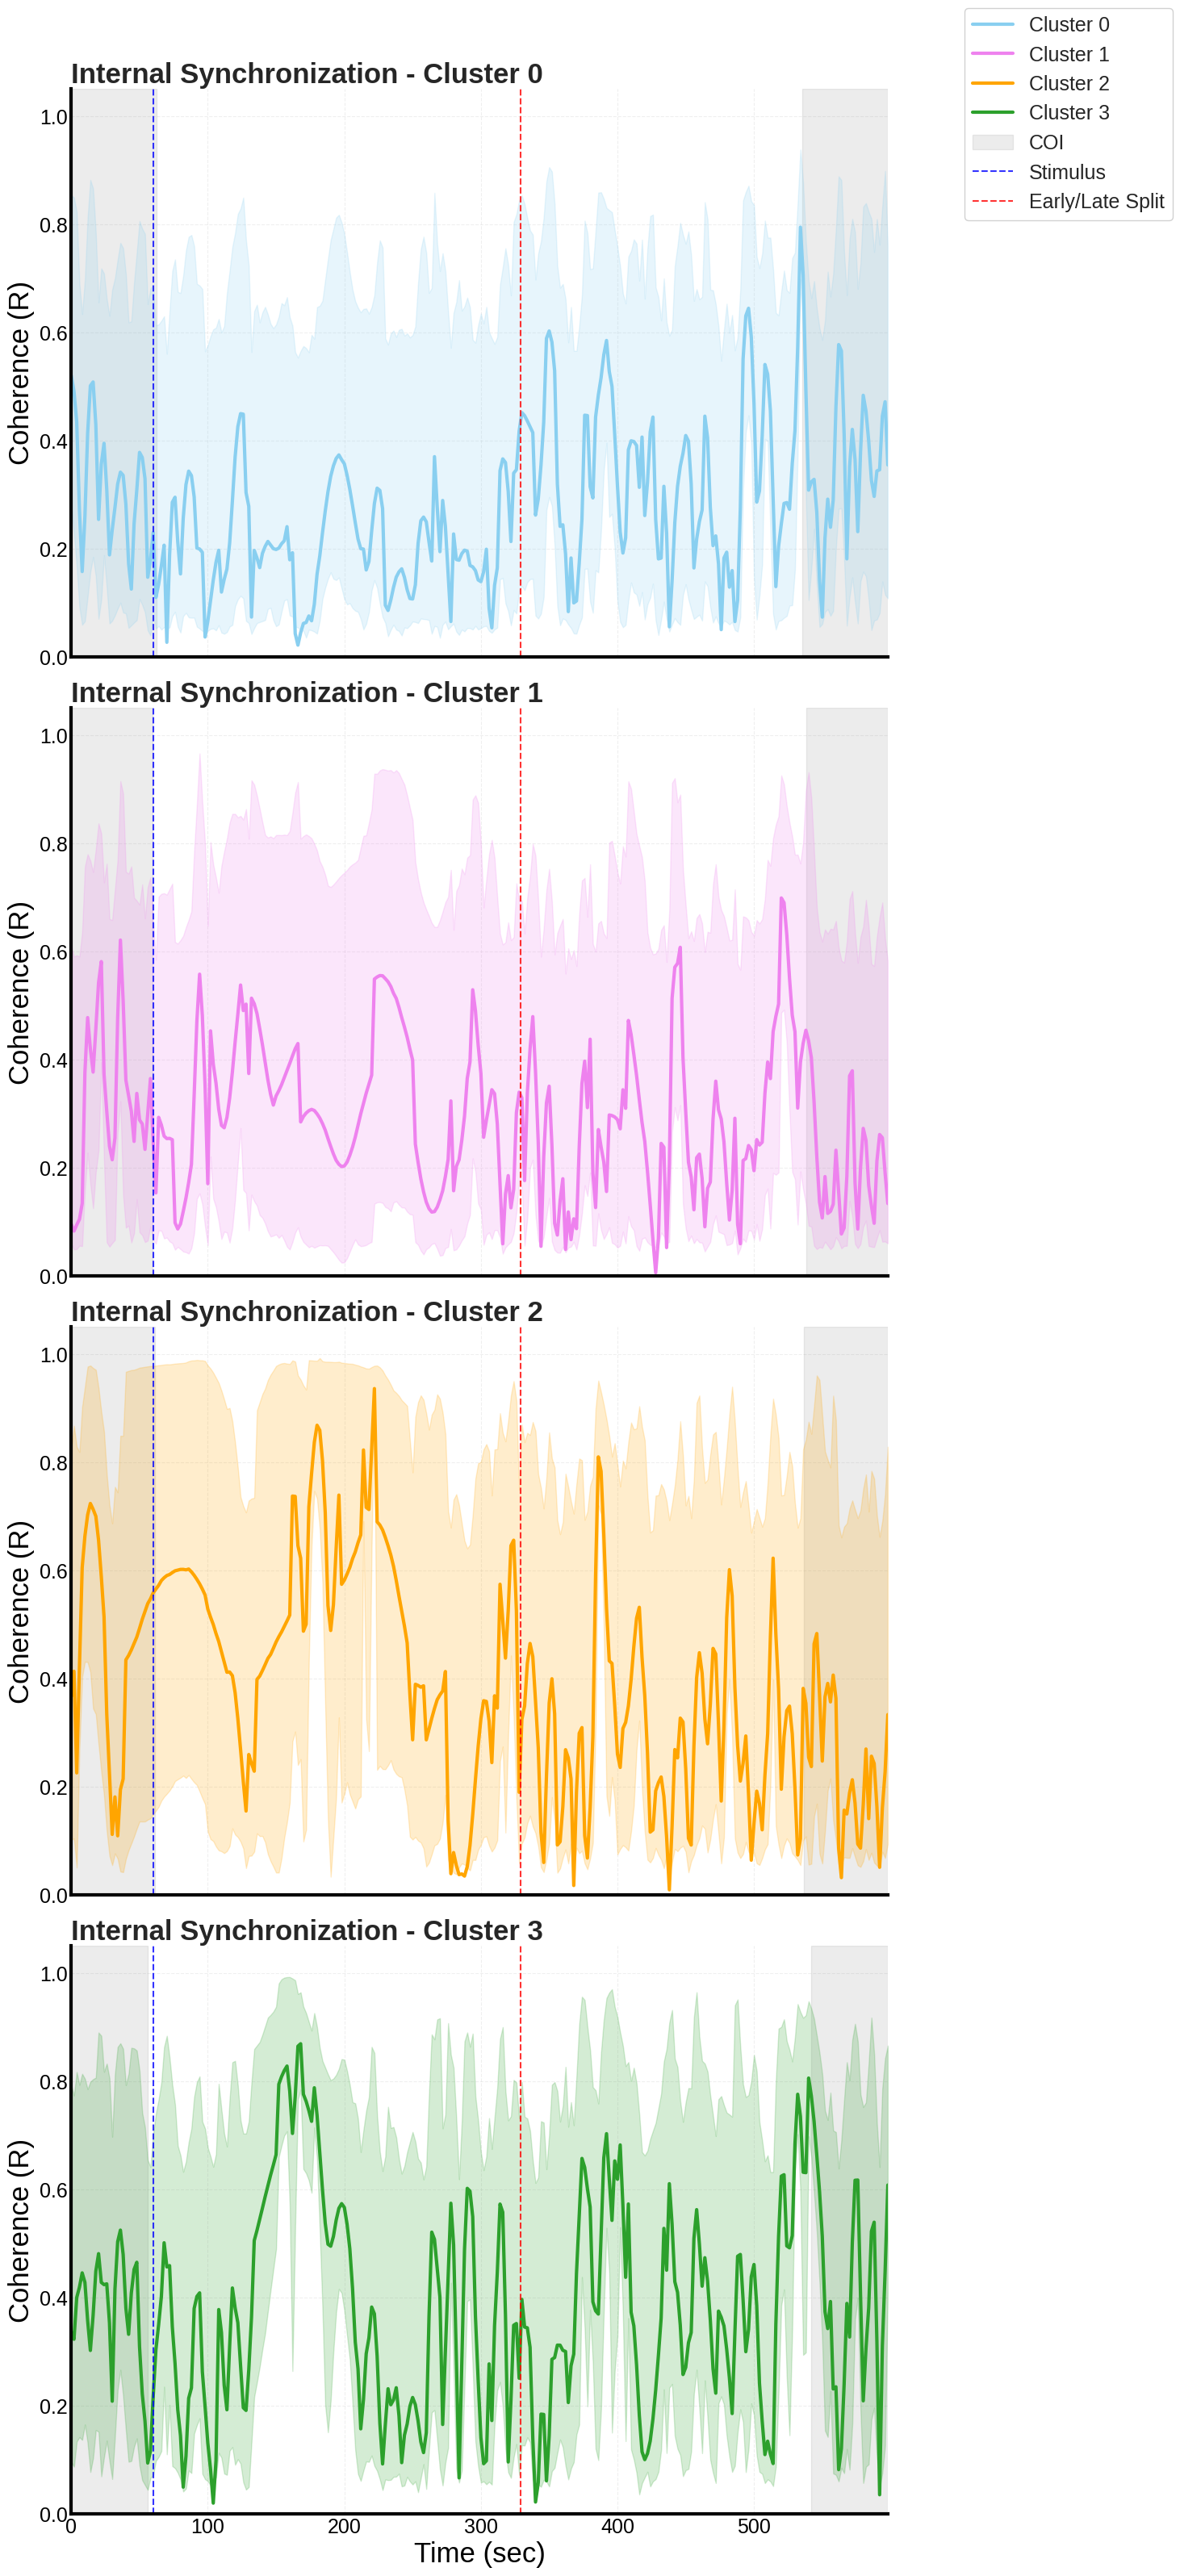

In [ ]:
print("Calculating internal Phase Coherence (R) per cluster with 95% CI and individualized COI...")

if 'df_combined_all_features' not in locals() or 'umap_df_pipeline' not in locals():
    print("Error: Necessary data not available.")
else:
    # Global aesthetic parameters
    title_font_size = globals().get('title_font_size_global', 25)
    label_font_size = globals().get('label_font_size_global', 25)
    tick_font_size = globals().get('tick_font_size_global', 18)
    legend_label_fs = globals().get('legend_label_font_size_global', 18)
    axis_line_width = globals().get('axis_line_width_global', 3)

    time_col = 'time'
    stimulus_onset = float(globals().get('stimulus_onset_time_global', 60) or 60.0)
    split_time_val = globals().get('post_stimulus_split_time_global')
    split_time = float(split_time_val) if split_time_val is not None else 172.0

    total_duration = df_combined_all_features[time_col].max()
    cluster_map = umap_df_pipeline.set_index('cell_id')['hierarchical_cluster'].to_dict()
    time_array = df_combined_all_features[time_col].values
    clusters = sorted(umap_df_pipeline['hierarchical_cluster'].unique())
    coherence_results = {}

    c_map = {0: '#89CFF0', 1: '#EE82EE', 2: '#FFA500', 3: '#2ca02c'}

    fig, axes = plt.subplots(len(clusters), 1, figsize=(14, 8 * len(clusters)), sharex=True)
    if len(clusters) == 1: axes = [axes]

    # Lists to collect handles and labels for the unified legend
    cluster_handles = []
    cluster_labels = []

    # Proxy artists for common elements
    coi_proxy = mpatches.Patch(color='gray', alpha=0.15, label='COI')
    stimulus_proxy = plt.Line2D([0], [0], color='blue', linestyle='--', alpha=0.8, label='Stimulus')
    split_proxy = plt.Line2D([0], [0], color='red', linestyle='--', alpha=0.8, label='Early/Late Split')

    for idx, cluster_id in enumerate(clusters):
        ax = axes[idx]
        cells_in_cluster = [cell for cell, clus in cluster_map.items() if clus == cluster_id]
        cluster_phase_cols = [f"{cell}_phase" for cell in cells_in_cluster if f"{cell}_phase" in df_combined_all_features.columns]
        cluster_period_cols = [f"{cell}_periods" for cell in cells_in_cluster if f"{cell}_periods" in df_combined_all_features.columns]

        if not cluster_phase_cols: continue

        phases = df_combined_all_features[cluster_phase_cols].values
        n_cells = phases.shape[1]
        complex_vectors = np.exp(1j * phases)
        R_t = np.abs(np.nanmean(complex_vectors, axis=1))
        coherence_results[cluster_id] = R_t

        n_boot = 1000
        boot_R = np.zeros((n_boot, len(time_array)))
        for i in range(n_boot):
            resample_idx = np.random.choice(n_cells, n_cells, replace=True)
            boot_R[i, :] = np.abs(np.nanmean(complex_vectors[:, resample_idx], axis=1))

        ci_low = np.percentile(boot_R, 2.5, axis=0)
        ci_high = np.percentile(boot_R, 97.5, axis=0)
        color = c_map.get(cluster_id, 'gray')

        # --- COI Shading ---
        if cluster_period_cols:
            avg_period_series = df_combined_all_features[cluster_period_cols].mean(axis=1).values
            representative_coi_period = np.nanmean(avg_period_series)
            if np.isnan(representative_coi_period) or representative_coi_period == 0: representative_coi_period = 8
            coi_w_seconds = 1.43 * representative_coi_period
            ax.axvspan(0, coi_w_seconds, color='gray', alpha=0.15)
            ax.axvspan(total_duration - coi_w_seconds, total_duration, color='gray', alpha=0.15)

        line, = ax.plot(time_array, R_t, label=f'Cluster {cluster_id} Coherence', color=color, linewidth=axis_line_width)
        cluster_handles.append(line)
        cluster_labels.append(f'Cluster {cluster_id} ')
        ax.fill_between(time_array, ci_low, ci_high, color=color, alpha=0.2)

        ax.axvline(stimulus_onset, color='blue', linestyle='--', alpha=0.8)
        ax.axvline(split_time, color='red', linestyle='--', alpha=0.8)

        ax.set_ylabel('Coherence (R)', fontsize=label_font_size, color='black')
        ax.set_ylim(0, 1.05)
        ax.set_xlim(0, total_duration)
        ax.tick_params(axis='both', labelsize=tick_font_size, labelcolor='black')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.set_title(f"Internal Synchronization - Cluster {cluster_id}", fontsize=title_font_size, loc='left', fontweight='bold')

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        for spine in ax.spines.values():
            spine.set_linewidth(axis_line_width)
            spine.set_color('black')

    axes[-1].set_xlabel('Time (sec)', fontsize=label_font_size, color='black')

    # Unified Legend
    final_handles = cluster_handles + [coi_proxy, stimulus_proxy, split_proxy]
    final_labels = cluster_labels + ['COI', 'Stimulus', 'Early/Late Split']
    fig.legend(final_handles, final_labels, loc='upper right', bbox_to_anchor=(1.05, 1),
               fontsize=legend_label_fs, frameon=True, facecolor='white', framealpha=0.9)

    plt.tight_layout(rect=[0, 0, 0.8, 0.98])
    plt.show()

    segments = {'Basal': time_array < stimulus_onset, 'Early Post-Stimulus': (time_array >= stimulus_onset) & (time_array < split_time), 'Late Post-Stimulus': time_array >= split_time}
    report_str = "\n--- Phase Coherence (R) Summary Report (Individualized COI) ---\n\n"
    for clus_id, R_vals in coherence_results.items():
        report_str += f"\nCluster {clus_id}:\n"
        for sn, mask in segments.items():
            report_str += f"  - {sn}: {np.nanmean(R_vals[mask]):.4f}\n"
    print(report_str)
    with open('statistical_report.txt', 'a') as f: f.write(report_str)

##Interaction Map

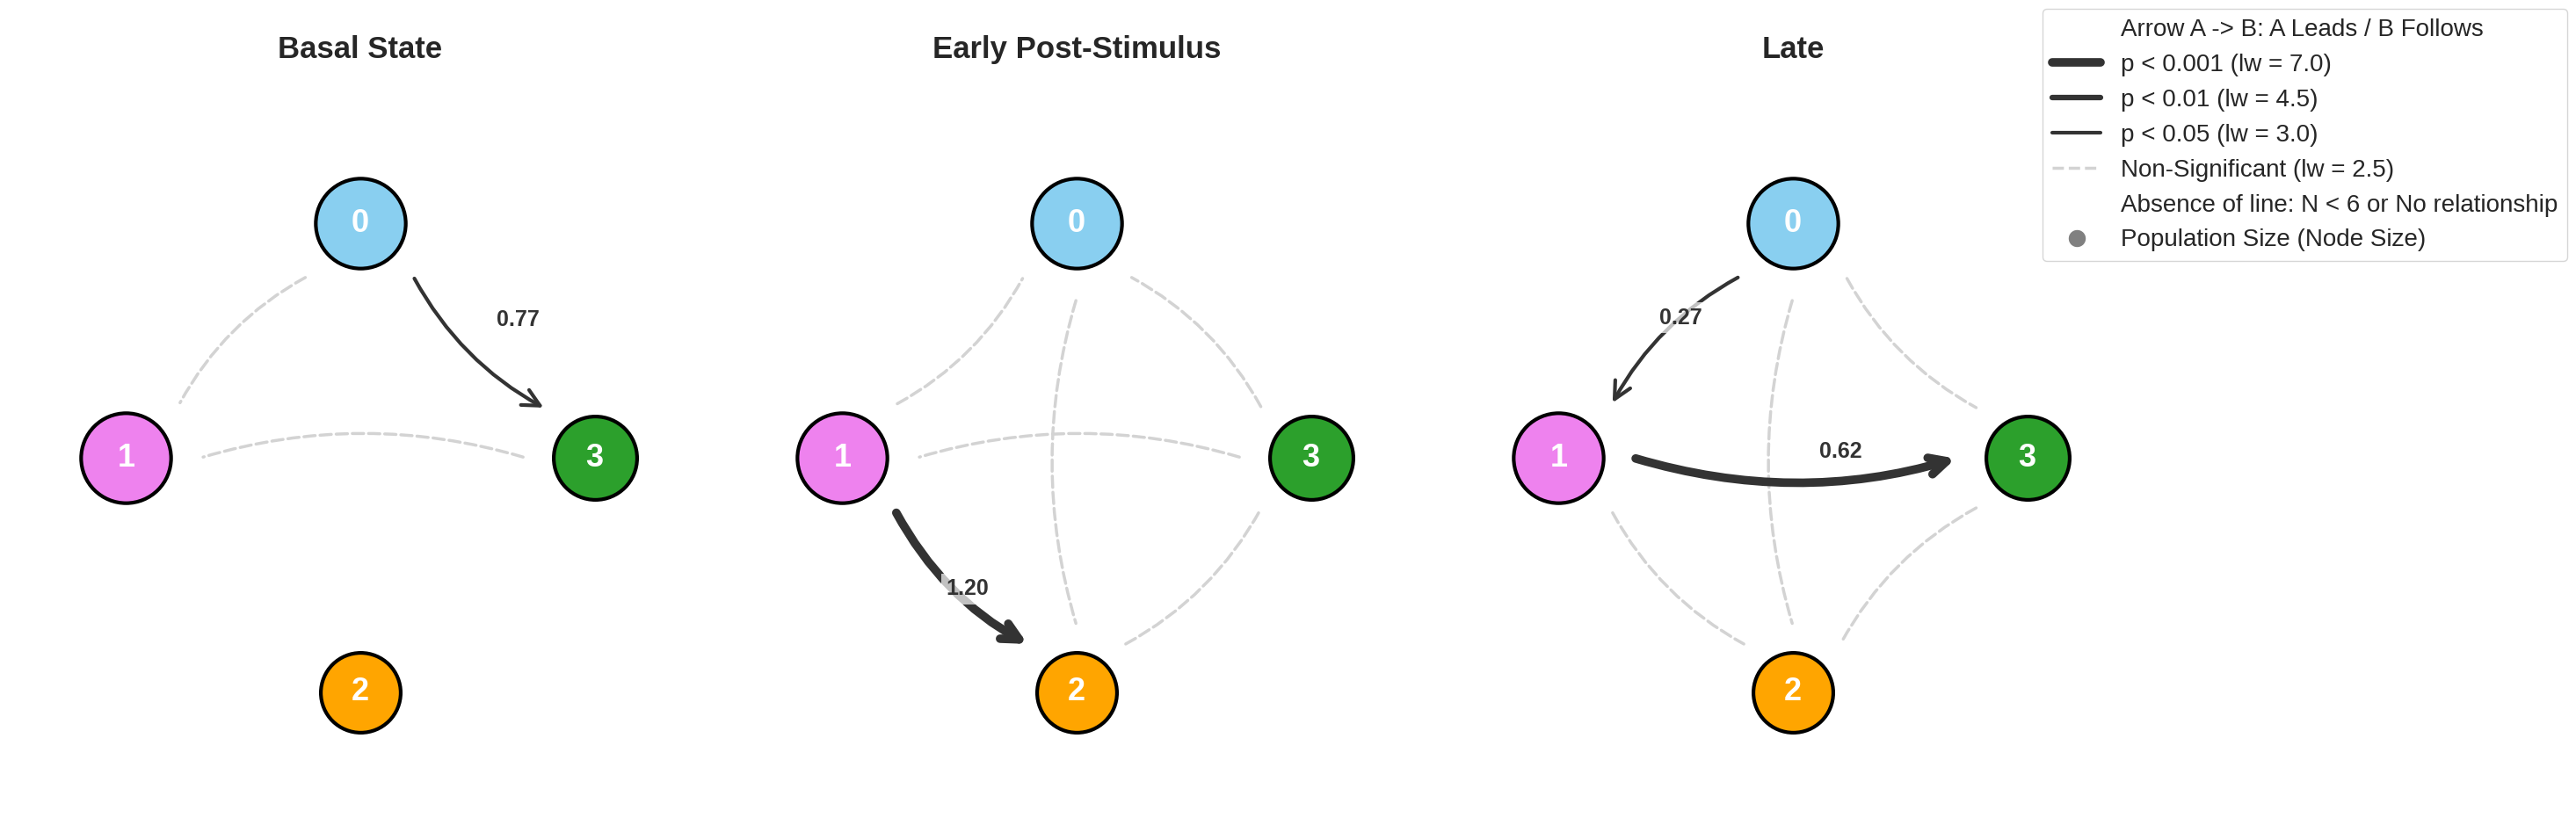

In [ ]:
# --- 1. Global Parameters and Data Check ---
df_phase_trajectories = globals().get('df_phase_trajectories')
umap_df_pipeline = globals().get('umap_df_pipeline')

if df_phase_trajectories is None or df_phase_trajectories.empty:
    print("Error: 'df_phase_trajectories' not found.")
elif umap_df_pipeline is None or umap_df_pipeline.empty:
    print("Error: 'umap_df_pipeline' not found.")
else:
    # Aesthetic parameters
    t_fs = globals().get('title_font_size_global', 25)
    tk_fs = globals().get('tick_font_size_global', 18)
    ax_lw = globals().get('axis_line_width_global', 3)

    MIN_N_STATS = 6

    present_clusters = sorted(umap_df_pipeline['hierarchical_cluster'].unique())
    full_color_pool = {0: '#89CFF0', 1: '#EE82EE', 2: '#FFA500', 3: '#2ca02c'}
    cluster_colors = {cid: full_color_pool.get(cid, 'gray') for cid in present_clusters}

    edge_color_neutral = '#333333'
    edge_color_ns = '#D3D3D3'

    cluster_counts = umap_df_pipeline['hierarchical_cluster'].value_counts(normalize=True).to_dict()
    def get_node_size(pct): return 1200 + (pct * 15000)
    node_sizes = {cid: get_node_size(pct) for cid, pct in cluster_counts.items()}

    n_nodes = len(present_clusters)
    node_positions = {cid: (np.cos(2*np.pi*i/n_nodes + np.pi/2), np.sin(2*np.pi*i/n_nodes + np.pi/2))
                      for i, cid in enumerate(present_clusters)}

    fig, axes = plt.subplots(1, 3, figsize=(30, 14), sharex=True, sharey=True)
    segments_to_plot = {'Basal': 'Basal State', 'Early': 'Early Post-Stimulus', 'Late': 'Late'}
    all_cluster_pairs = list(combinations(present_clusters, 2))

    for ax_idx, (seg_key, title) in enumerate(segments_to_plot.items()):
        ax = axes[ax_idx]
        ax.set_title(title, fontsize=t_fs, fontweight='bold', pad=40)
        ax.set_aspect('equal')

        for cid, pos in node_positions.items():
            ax.scatter(pos[0], pos[1], s=node_sizes.get(cid, 1500), color=cluster_colors[cid], edgecolor='black', linewidth=ax_lw, zorder=5)
            ax.text(pos[0], pos[1], str(cid), color='white', ha='center', va='center', fontsize=tk_fs+8, fontweight='bold', zorder=6)

        for c1, c2 in all_cluster_pairs:
            pair_str = f"{c1}-{c2}"
            data = df_phase_trajectories[(df_phase_trajectories['Pair'] == pair_str) & (df_phase_trajectories['Segment'] == seg_key)]['Delta_Phi'].dropna()

            if len(data) >= MIN_N_STATS:
                _, p = wilcoxon(data)
                mean_val = data.mean()
                u_cid, v_cid = (c1, c2) if mean_val > 0 else (c2, c1)
                p1, p2 = np.array(node_positions[u_cid]), np.array(node_positions[v_cid])
                vec = p2 - p1
                dist = np.linalg.norm(vec)
                # Adjusted multiplier for longer arrows
                u_r = np.sqrt(node_sizes[u_cid]/1200) * 0.15
                v_r = np.sqrt(node_sizes[v_cid]/1200) * 0.15
                start, end = p1 + (vec / dist) * u_r, p2 - (vec / dist) * v_r

                if p < 0.05:
                    lw = 7.0 if p < 0.001 else (4.5 if p < 0.01 else 3.0)
                    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color=edge_color_neutral, lw=lw, connectionstyle='arc3,rad=0.15', mutation_scale=35), zorder=2)
                    mid = (start + end) / 2

                    # --- Apply a radial offset to the text position to prevent overlap ---
                    text_radial_offset = 0.1 # This value can be tuned as needed
                    mid_vec = np.array([mid[0], mid[1]])
                    mid_dist = np.linalg.norm(mid_vec)

                    if mid_dist > 0: # Avoid division by zero if mid is (0,0)
                        text_pos = mid_vec + (mid_vec / mid_dist) * text_radial_offset
                    else:
                        text_pos = mid_vec # If mid is (0,0), no offset

                    ax.text(text_pos[0], text_pos[1], f"{abs(mean_val):.2f}", color=edge_color_neutral, fontsize=tk_fs, fontweight='bold', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
                else:
                    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='-', color=edge_color_ns, lw=2.5, ls='--', connectionstyle='arc3,rad=0.15'), zorder=1)
            elif len(data) >= 5:
                 # Visualization only, no interaction line plotted to maintain rigor on leadership
                 pass

        ax.axis('off')
        ax.set_xlim(-1.5, 1.5)
        ax.set_ylim(-1.5, 1.5)

    legend_elements = [
        plt.Line2D([0], [0], color='none', label='Arrow A -> B: A Leads / B Follows'),
        plt.Line2D([0], [0], color=edge_color_neutral, lw=7, label='p < 0.001 (lw = 7.0)'),
        plt.Line2D([0], [0], color=edge_color_neutral, lw=4.5, label='p < 0.01 (lw = 4.5)'),
        plt.Line2D([0], [0], color=edge_color_neutral, lw=3.0, label='p < 0.05 (lw = 3.0)'),
        plt.Line2D([0], [0], color=edge_color_ns, lw=2.5, ls='--', label='Non-Significant (lw = 2.5)'),
        plt.Line2D([0], [0], color='none', label='Absence of line: N < 6 or No relationship'),
        plt.Line2D([0], [0], marker='o', color='w', label='Population Size (Node Size)', markerfacecolor='gray', markersize=15)


    ]

    fig.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.98, 0.85), fontsize=20, frameon=True)
    plt.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()